Vaibhav Yadav
2401CS70

Task 1

experiment axial: loaded from FBG biaxial tilt sensor.xlsx[Experiment axial ]
experiment transverse: loaded from FBG biaxial tilt sensor.xlsx[Experiment transverse ]
AXIAL DATASET
Observations: 37 | Columns: 7 (1 target + 6 features)
Missing values per column:
 theta    0
FBG1     0
FBG2     0
dL1      0
dL2      0
dDiff    0
dAvg     0
Duplicate rows: 2 | Unique tilt angles: 19

Descriptive statistics:
             mean    median       std         var       min       max
theta     0.00000     0.000  52.12165  2716.66667   -90.000    90.000
FBG1   1535.21511  1535.216   0.02446     0.00060  1535.178  1535.248
FBG2   1547.35038  1547.349   0.02423     0.00059  1547.314  1547.385
dL1      -0.89189     0.000  24.45834   598.21021   -38.000    32.000
dL2      -0.62162    -2.000  24.23078   587.13063   -37.000    34.000
dDiff    -0.27027     0.000  48.66647  2368.42492   -71.000    68.000
dAvg     -0.75676    -0.500   0.75113     0.56419    -3.000     0.500

Tilt-angle distribution (angle: 

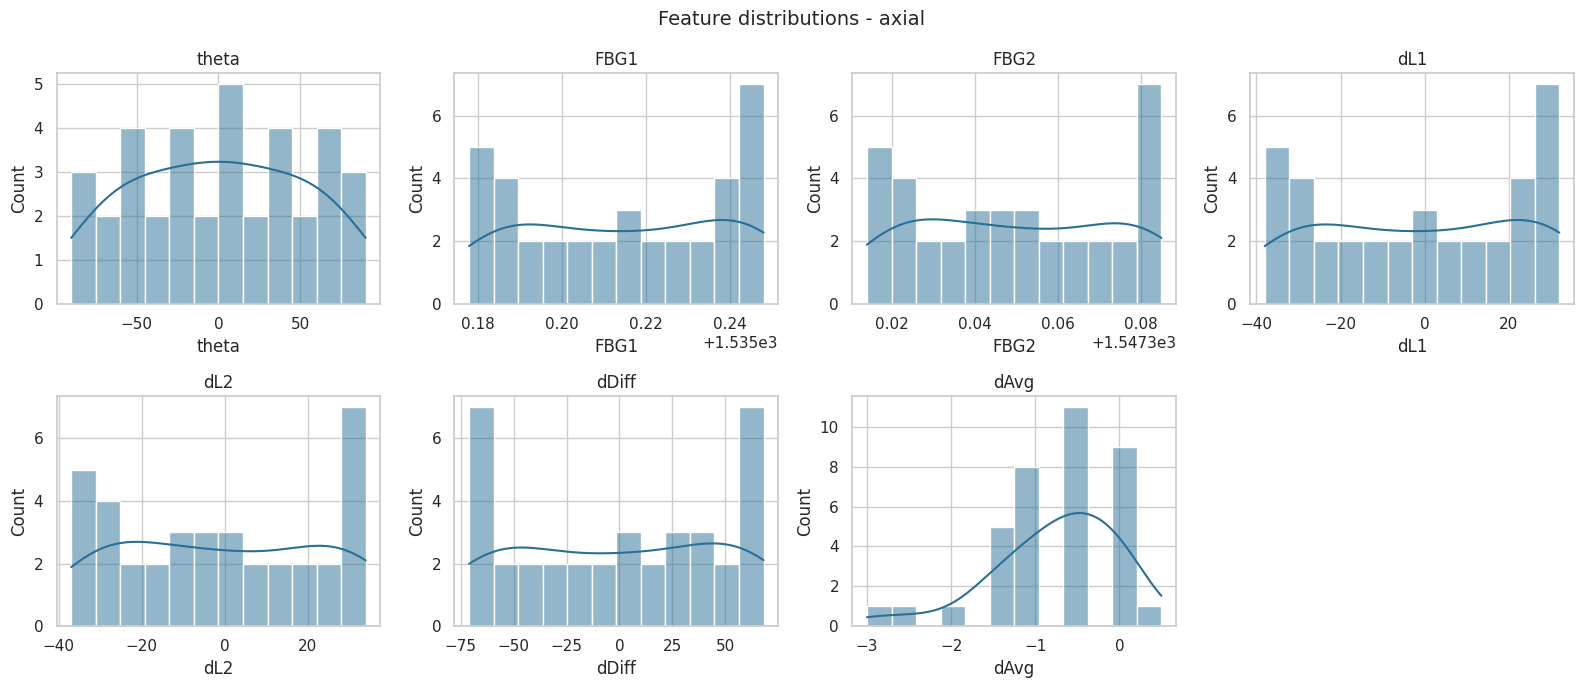


Repeated tilt angles and spread of their wavelength measurements:
 theta  n  FBG1_mean  FBG1_range  FBG2_mean  FBG2_range  dL1_mean  dL1_range  dL2_mean  dL2_range
   -80  2 1535.18000       0.000 1547.38500       0.000 -36.00000          0  34.00000          0
   -70  2 1535.18250       0.001 1547.38400       0.000 -33.50000          1  33.00000          0
   -60  2 1535.18500       0.000 1547.38050       0.001 -31.00000          0  29.50000          1
   -50  2 1535.18900       0.000 1547.37650       0.001 -27.00000          0  25.50000          1
   -40  2 1535.19350       0.001 1547.37200       0.000 -22.50000          1  21.00000          0
   -30  2 1535.19850       0.001 1547.36700       0.000 -17.50000          1  16.00000          0
   -20  2 1535.20400       0.002 1547.36100       0.000 -12.00000          2  10.00000          0
   -10  2 1535.20950       0.001 1547.35500       0.000  -6.50000          1   4.00000          0
     0  3 1535.21533       0.002 1547.34967       0

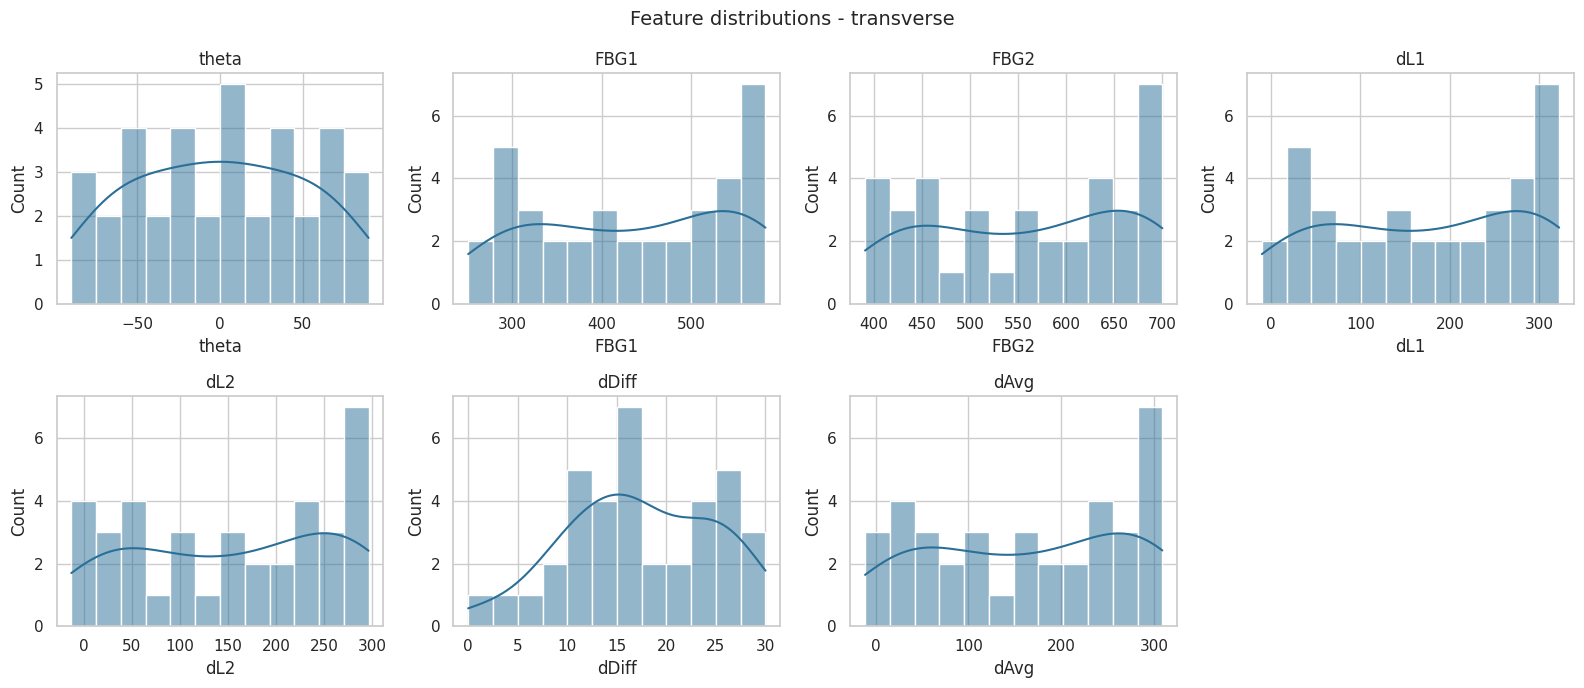


Repeated tilt angles and spread of their wavelength measurements:
 theta  n  FBG1_mean  FBG1_range  FBG2_mean  FBG2_range  dL1_mean  dL1_range  dL2_mean  dL2_range
   -80  2  561.00000          14  675.50000          13 300.00000         14 271.50000         13
   -70  2  536.50000          17  653.50000          15 275.50000         17 249.50000         15
   -60  2  499.50000          27  619.00000          26 238.50000         27 215.00000         26
   -50  2  455.00000          32  579.00000          26 194.00000         32 175.00000         26
   -40  2  408.50000          35  535.00000          36 147.50000         35 131.00000         36
   -30  2  356.50000          33  482.50000          33  95.50000         33  78.50000         33
   -20  2  314.00000          28  441.50000          25  53.00000         28  37.50000         25
   -10  2  282.50000           5  416.50000           7  21.50000          5  12.50000          7
     0  3  267.66667          40  407.33333        

In [13]:

import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
os.makedirs('figs', exist_ok=True)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

COLS = ['theta', 'FBG1', 'FBG2', 'dL1', 'dL2', 'dDiff', 'dAvg']

def load_exp(keyword):
    csvs = [f for f in os.listdir('.') if f.lower().endswith('.csv')
            and keyword in f.lower().replace('_', ' ')]
    if csvs:
        raw, src = pd.read_csv(csvs[0], header=None), csvs[0]
    else:
        xl = [f for f in os.listdir('.') if f.lower().endswith('.xlsx')]
        if not xl:
            raise FileNotFoundError(f"Upload the '{keyword}' sheet (CSV or the full .xlsx) to the Files panel.")
        sheets = pd.read_excel(xl[0], sheet_name=None, header=None)
        key = [k for k in sheets if keyword in k.lower()][0]
        raw, src = sheets[key], f'{xl[0]}[{key}]'
    raw = raw.iloc[:, :7].copy(); raw.columns = COLS          # first row is data, not a header
    raw = raw.apply(pd.to_numeric, errors='coerce').dropna(how='all').reset_index(drop=True)
    print(f'{keyword}: loaded from {src}')
    return raw

DATA = {'axial': load_exp('experiment axial'), 'transverse': load_exp('experiment transverse')}

for ds, df in DATA.items():
    print('=' * 80); print(f'{ds.upper()} DATASET'); print('=' * 80)
    print(f'Observations: {len(df)} | Columns: {df.shape[1]} (1 target + {df.shape[1]-1} features)')
    print('Missing values per column:\n', df.isna().sum().to_string())
    print('Duplicate rows:', int(df.duplicated().sum()), '| Unique tilt angles:', df.theta.nunique())
    print('\nDescriptive statistics:')
    print(df.agg(['mean', 'median', 'std', 'var', 'min', 'max']).T.round(5))
    print('\nTilt-angle distribution (angle: count):')
    print(df.theta.value_counts().sort_index().to_string())


    fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
    for ax, c in zip(axes, COLS):
        sns.histplot(df[c], kde=True, bins=12, ax=ax, color='#2a6f97'); ax.set_title(c)
    axes[-1].axis('off')
    fig.suptitle(f'Feature distributions - {ds}', fontsize=14); plt.tight_layout()
    plt.savefig(f'figs/t1_dist_{ds}.png', dpi=200); plt.show()


    rows = []
    for ang, grp in df.groupby('theta'):
        if len(grp) > 1:
            r = {'theta': ang, 'n': len(grp)}
            for c in ['FBG1', 'FBG2', 'dL1', 'dL2']:
                r[c + '_mean'] = grp[c].mean(); r[c + '_range'] = grp[c].max() - grp[c].min()
            rows.append(r)
    rep = pd.DataFrame(rows)
    print('\nRepeated tilt angles and spread of their wavelength measurements:')
    print(rep.round(5).to_string(index=False) if len(rep) else 'No repeated angles found.')


task 2


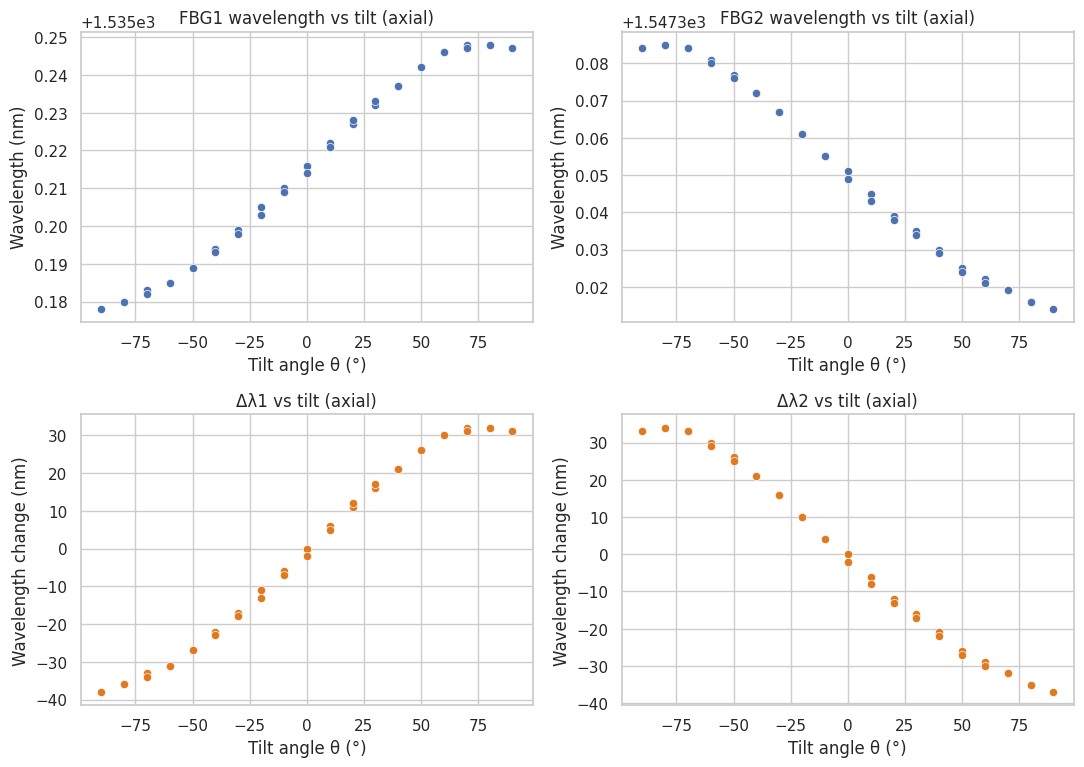

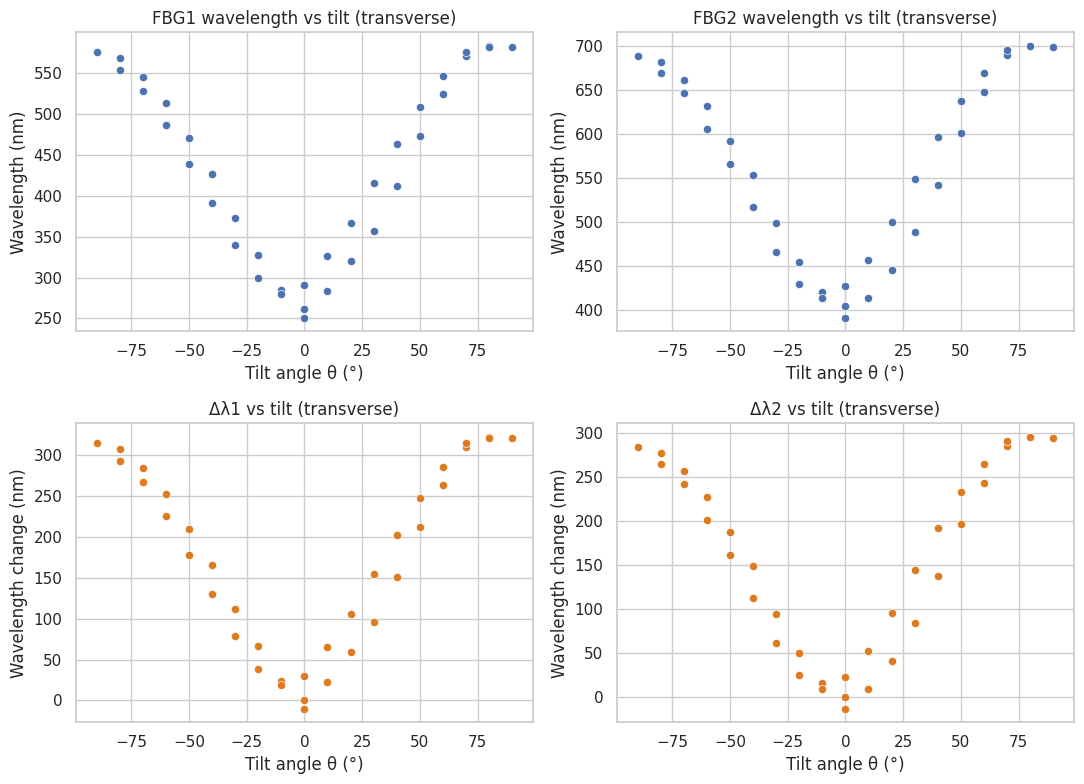

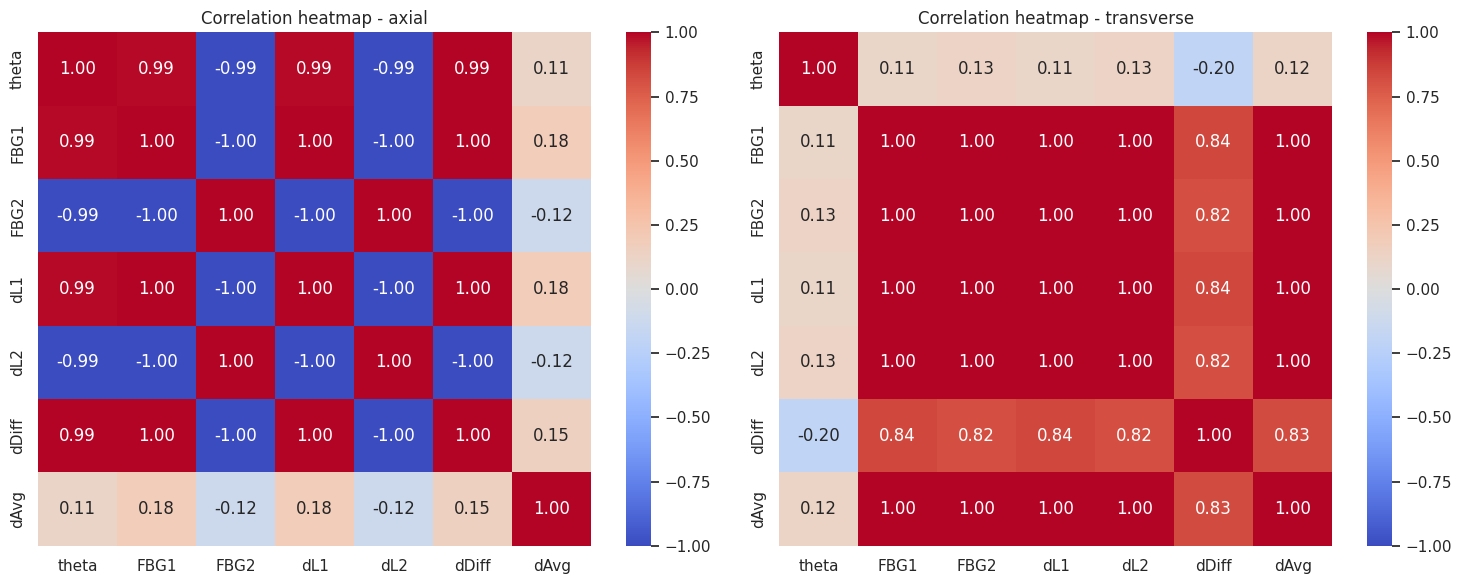

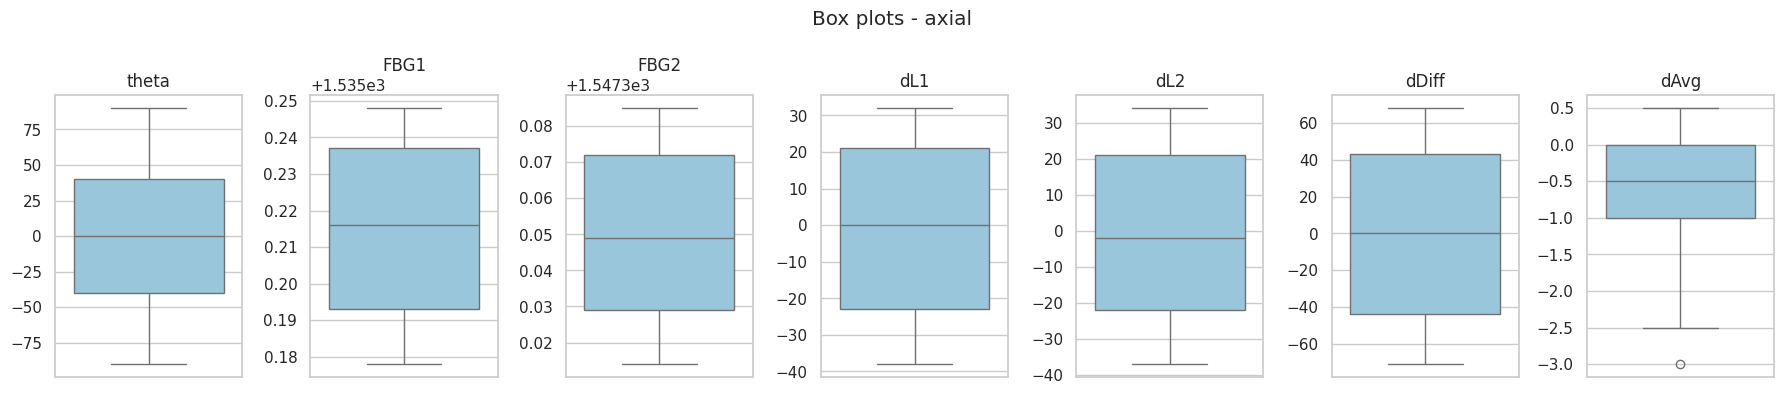

IQR-rule outlier counts (axial): {'theta': 0, 'FBG1': 0, 'FBG2': 0, 'dL1': 0, 'dL2': 0, 'dDiff': 0, 'dAvg': 1}


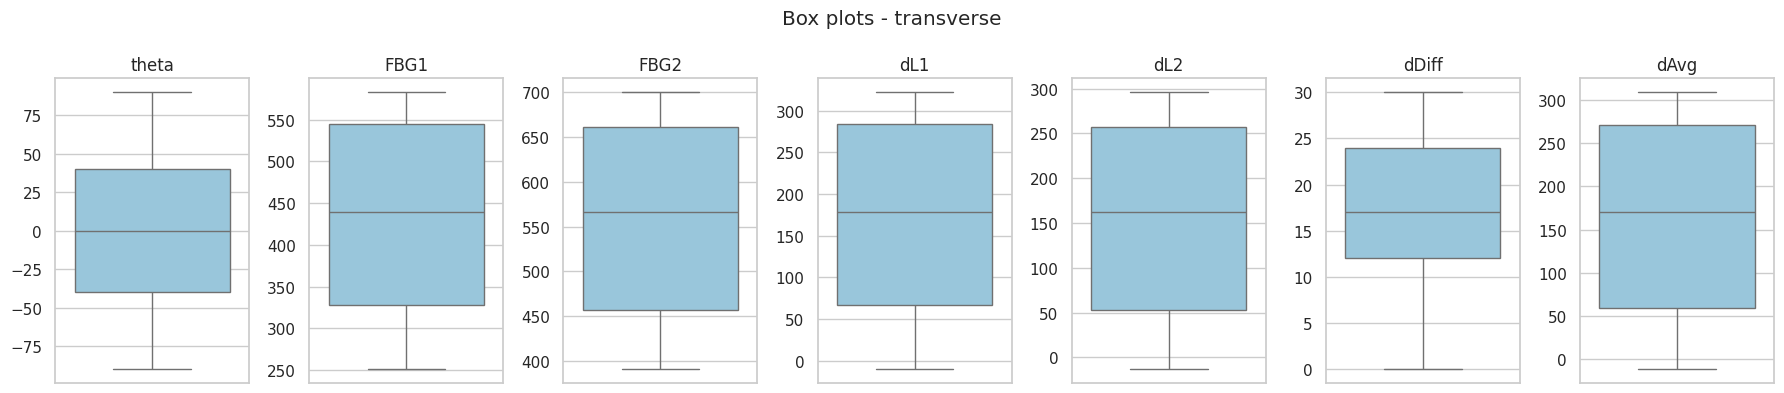

IQR-rule outlier counts (transverse): {'theta': 0, 'FBG1': 0, 'FBG2': 0, 'dL1': 0, 'dL2': 0, 'dDiff': 0, 'dAvg': 0}

[axial] train rows=30, test rows=7
  Raw             train mean=[ 3.3 -4.7], std=[23.0393 23.0162], min=[-34 -37], max=[32 33]
  StandardScaler  train mean=[0. 0.], std=[1. 1.], min=[-1.619  -1.4034], max=[1.2457 1.638 ]
  MinMaxScaler    train mean=[0.5652 0.4614], std=[0.3491 0.3288], min=[0. 0.], max=[1. 1.]
  MinMax applied to TEST (can leave [0,1] because fit used train only): min [-0.061  0.343] max [0.697 1.014]

[transverse] train rows=30, test rows=7
  Raw             train mean=[168.7667 152.3333], std=[112.0793 106.1958], min=[-10 -13], max=[322 296]
  StandardScaler  train mean=[-0. -0.], std=[1. 1.], min=[-1.595  -1.5569], max=[1.3672 1.3528]
  MinMaxScaler    train mean=[0.5385 0.5351], std=[0.3376 0.3437], min=[0. 0.], max=[1. 1.]
  MinMax applied to TEST (can leave [0,1] because fit used train only): min [0.208 0.175] max [0.979 0.964]


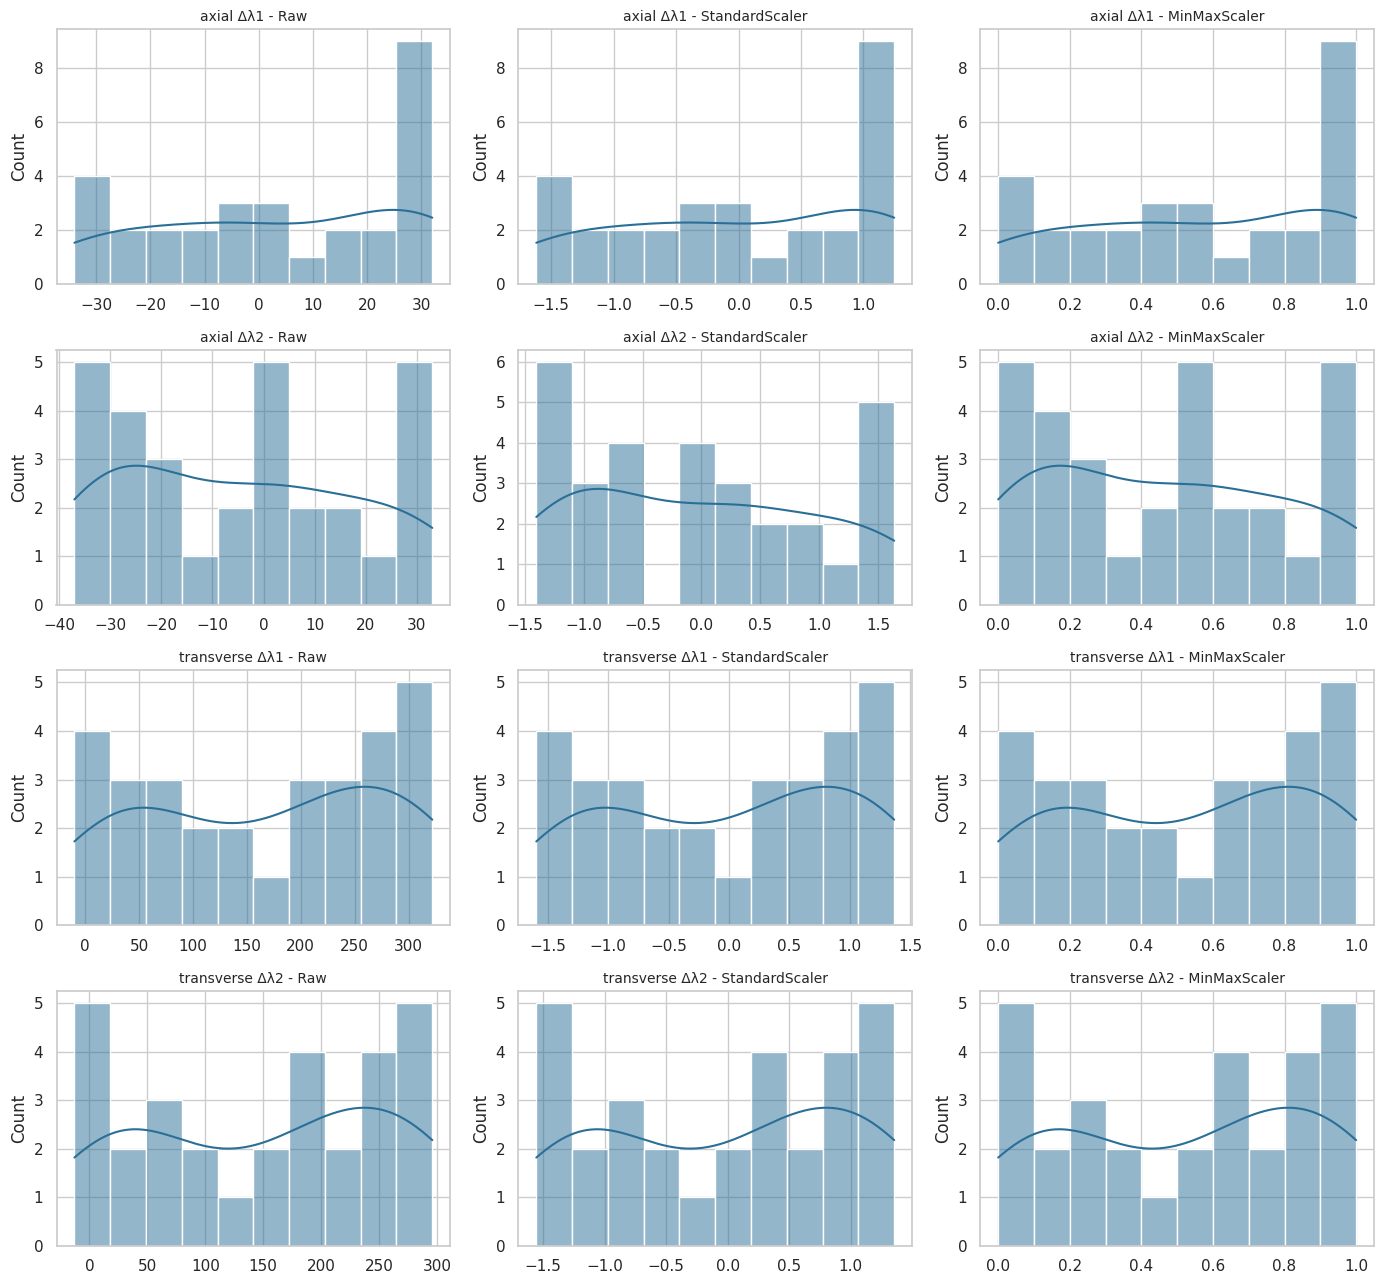

In [14]:
# TASK 2: Visualization & preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit


for ds, df in DATA.items():
    fig, ax = plt.subplots(2, 2, figsize=(11, 8))
    for j, c in enumerate(['FBG1', 'FBG2']):
        sns.scatterplot(x=df.theta, y=df[c], ax=ax[0, j], s=35); ax[0, j].set_title(f'{c} wavelength vs tilt ({ds})')
        ax[0, j].set_xlabel('Tilt angle θ (°)'); ax[0, j].set_ylabel('Wavelength (nm)')
    for j, c in enumerate(['dL1', 'dL2']):
        sns.scatterplot(x=df.theta, y=df[c], ax=ax[1, j], s=35, color='#e07a1f'); ax[1, j].set_title(f'Δλ{j+1} vs tilt ({ds})')
        ax[1, j].set_xlabel('Tilt angle θ (°)'); ax[1, j].set_ylabel('Wavelength change (nm)')
    plt.tight_layout(); plt.savefig(f'figs/t2_scatter_{ds}.png', dpi=200); plt.show()


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (ds, df) in zip(axes, DATA.items()):
    sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax); ax.set_title(f'Correlation heatmap - {ds}')
plt.tight_layout(); plt.savefig('figs/t2_heatmap.png', dpi=200); plt.show()

for ds, df in DATA.items():
    fig, axes = plt.subplots(1, 7, figsize=(18, 4))
    for ax, c in zip(axes, COLS):
        sns.boxplot(y=df[c], ax=ax, color='#8ecae6'); ax.set_title(c); ax.set_ylabel('')
    fig.suptitle(f'Box plots - {ds}'); plt.tight_layout(); plt.savefig(f'figs/t2_box_{ds}.png', dpi=200); plt.show()
    out = {}
    for c in COLS:
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        out[c] = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    print(f'IQR-rule outlier counts ({ds}):', out)

fig, axes = plt.subplots(4, 3, figsize=(14, 13)); r = 0
for ds, df in DATA.items():
    X = df[['dL1', 'dL2']].values; g = df.theta.round(4).values
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, groups=g))
    ss, mm = StandardScaler().fit(X[tr]), MinMaxScaler().fit(X[tr])
    versions = {'Raw': X[tr], 'StandardScaler': ss.transform(X[tr]), 'MinMaxScaler': mm.transform(X[tr])}
    print(f'\n[{ds}] train rows={len(tr)}, test rows={len(te)}')
    for k, v in versions.items():
        print(f'  {k:15s} train mean={v.mean(0).round(4)}, std={v.std(0).round(4)}, min={v.min(0).round(4)}, max={v.max(0).round(4)}')
    print('  MinMax applied to TEST (can leave [0,1] because fit used train only): min', mm.transform(X[te]).min(0).round(3), 'max', mm.transform(X[te]).max(0).round(3))
    for k, name in enumerate(['Δλ1', 'Δλ2']):
        for j, (vn, v) in enumerate(versions.items()):
            sns.histplot(v[:, k], bins=10, kde=True, ax=axes[r, j], color='#2a6f97'); axes[r, j].set_title(f'{ds} {name} - {vn}', fontsize=10)
        r += 1
plt.tight_layout(); plt.savefig('figs/t2_scaling.png', dpi=200); plt.show()

task 3


[axial] max|computed - sheet| : dDiff=2.274e-10, dAvg=0.000e+00
[transverse] max|computed - sheet| : dDiff=0.000e+00, dAvg=0.000e+00

Pearson r (feature vs tilt angle):
         axial  transverse
dL1    0.9917      0.1082
dL2   -0.9939      0.1288
dDiff  0.9932     -0.2007
dAvg   0.1135      0.1183


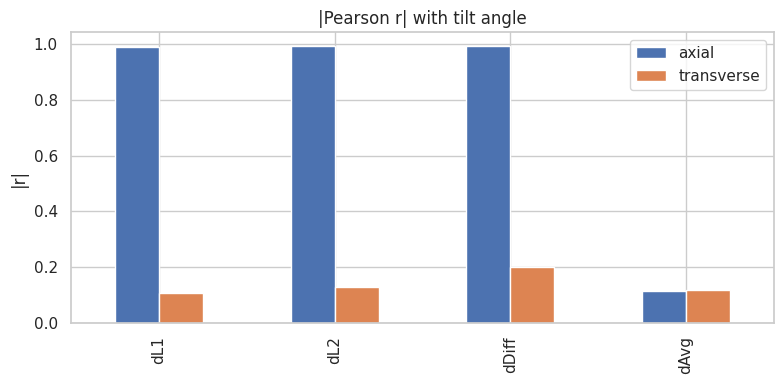


Feature-configuration comparison:
   Dataset Config   Features                 Pearson_r  MLR_RMSE  MLR_R2  Poly2_RMSE  Poly2_R2
     axial     F1    dL1+dL2    dL1:+0.992, dL2:-0.994    6.8223  0.9824      4.7948    0.9913
     axial     F2      dDiff              dDiff:+0.993    6.2762  0.9851      6.5364    0.9838
     axial     F3       dAvg               dAvg:+0.114   57.0475 -0.2312     55.1035   -0.1487
     axial     F4 dDiff+dAvg dDiff:+0.993, dAvg:+0.114    6.8223  0.9824      4.7948    0.9913
transverse     F1    dL1+dL2    dL1:+0.108, dL2:+0.129   45.9447  0.2014     30.7594    0.6421
transverse     F2      dDiff              dDiff:-0.201   51.8692 -0.0178     53.1484   -0.0687
transverse     F3       dAvg               dAvg:+0.118   51.8411 -0.0167     51.9131   -0.0196
transverse     F4 dDiff+dAvg dDiff:-0.201, dAvg:+0.118   45.9447  0.2014     30.7594    0.6421
Most informative configuration for axial: F4 (lowest mean RMSE).
Most informative configuration for transverse

In [15]:
# TASK 3: Feature engineering & selection
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metrics(y, p):
    mse = mean_squared_error(y, p)
    return dict(MAE=mean_absolute_error(y, p), MSE=mse, RMSE=float(np.sqrt(mse)), R2=r2_score(y, p))

def cv_eval(est, X, y, groups, grid=None, n_outer=5, n_inner=3):
    """5-fold GROUPED CV (same tilt angle never split across folds).
    If grid is given, hyperparameters are tuned by an inner grouped CV on the TRAINING fold only (no leakage).
    Scalers live inside the pipeline, so they are also fitted on training folds only."""
    n_outer = min(n_outer, len(np.unique(groups)))
    oof = np.zeros(len(y)); times, tr_rmse, fold_rmse, best = [], [], [], []
    for tr, te in GroupKFold(n_splits=n_outer).split(X, y, groups):
        t0 = time.perf_counter()
        if grid:
            m = GridSearchCV(clone(est), grid, cv=GroupKFold(n_splits=min(n_inner, len(np.unique(groups[tr])))),
                             scoring='neg_root_mean_squared_error')
            m.fit(X[tr], y[tr], groups=groups[tr]); best.append(m.best_params_)
        else:
            m = clone(est).fit(X[tr], y[tr])
        times.append(time.perf_counter() - t0)
        oof[te] = m.predict(X[te])
        tr_rmse.append(np.sqrt(mean_squared_error(y[tr], m.predict(X[tr]))))
        fold_rmse.append(np.sqrt(mean_squared_error(y[te], oof[te])))
    out = metrics(y, oof)
    out.update(Time=float(np.mean(times)), TrainRMSE=float(np.mean(tr_rmse)), FoldRMSE_std=float(np.std(fold_rmse)), oof=oof, best=best)
    return out

FE = {}
for ds, df in DATA.items():
    d = df[['theta', 'dL1', 'dL2']].copy()
    d['dDiff'] = d.dL1 - d.dL2
    d['dAvg'] = (d.dL1 + d.dL2) / 2
    FE[ds] = d
    print(f'[{ds}] max|computed - sheet| : dDiff={np.nanmax(np.abs(d.dDiff - df.dDiff)):.3e}, dAvg={np.nanmax(np.abs(d.dAvg - df.dAvg)):.3e}')

FEATS = {'F1': ['dL1', 'dL2'], 'F2': ['dDiff'], 'F3': ['dAvg'], 'F4': ['dDiff', 'dAvg']}
FEAT_MAIN = 'F1'

def get_xyg(ds, feat=FEAT_MAIN, absolute=False):
    d = FE[ds]
    y = d.theta.abs().values if absolute else d.theta.values
    return d[FEATS[feat]].values, y, d.theta.round(4).values


CORR = pd.DataFrame({ds: FE[ds][['dL1', 'dL2', 'dDiff', 'dAvg']].corrwith(FE[ds].theta) for ds in FE})
print('\nPearson r (feature vs tilt angle):\n', CORR.round(4))
CORR.abs().plot.bar(figsize=(8, 4), title='|Pearson r| with tilt angle'); plt.ylabel('|r|'); plt.tight_layout()
plt.savefig('figs/t3_corr.png', dpi=200); plt.show()

mlr = Pipeline([('sc', StandardScaler()), ('m', LinearRegression())])
poly2 = Pipeline([('sc', StandardScaler()), ('pf', PolynomialFeatures(2, include_bias=False)), ('m', LinearRegression())])
rows = []
for ds in DATA:
    for f, cols in FEATS.items():
        X, y, g = get_xyg(ds, f)
        a, b = cv_eval(mlr, X, y, g), cv_eval(poly2, X, y, g)
        r = ', '.join(f'{c}:{FE[ds][c].corr(FE[ds].theta):+.3f}' for c in cols)
        rows.append(dict(Dataset=ds, Config=f, Features='+'.join(cols), Pearson_r=r,
                         MLR_RMSE=a['RMSE'], MLR_R2=a['R2'], Poly2_RMSE=b['RMSE'], Poly2_R2=b['R2']))
FEAT_TABLE = pd.DataFrame(rows)
print('\nFeature-configuration comparison:'); print(FEAT_TABLE.round(4).to_string(index=False))
for ds in DATA:
    t = FEAT_TABLE[FEAT_TABLE.Dataset == ds].copy(); t['avg'] = (t.MLR_RMSE + t.Poly2_RMSE) / 2
    print(f'Most informative configuration for {ds}: {t.loc[t.avg.idxmin(), "Config"]} (lowest mean RMSE).')
print('Note: F4 is an invertible linear transform of F1, so linear models give identical F1/F4 results.')

task 4


===== AXIAL - statistical models (grouped 5-fold CV, features F1) =====
                  MAE       MSE     RMSE       R2     Time
SLR           5.42835  48.34303  6.95292  0.98171  0.00233
MLR           5.35829  46.54434  6.82234  0.98239  0.00163
Poly (deg 2)  4.09002  22.99012  4.79480  0.99130  0.00200
Poly (deg 3)  2.89979  33.02500  5.74674  0.98751  0.00207
Ridge         5.24544  47.67662  6.90483  0.98196  0.11808
Lasso         5.21720  44.95964  6.70520  0.98299  0.13442
Elastic Net   5.15665  46.47679  6.81739  0.98242  0.38710
  Ridge: alpha/l1_ratio chosen per outer fold -> [{'alpha': 0.01}, {'alpha': 1.0}, {'alpha': 1.0}, {'alpha': 0.31623}, {'alpha': 0.00316}]
  Lasso: alpha/l1_ratio chosen per outer fold -> [{'alpha': 0.31623}, {'alpha': 0.31623}, {'alpha': 0.1}, {'alpha': 0.31623}, {'alpha': 0.01}]
  Elastic Net: alpha/l1_ratio chosen per outer fold -> [{'alpha': 0.001, 'l1_ratio': 0.2}, {'alpha': 0.03162, 'l1_ratio': 0.2}, {'alpha': 0.03162, 'l1_ratio': 0.2}, {'alpha'

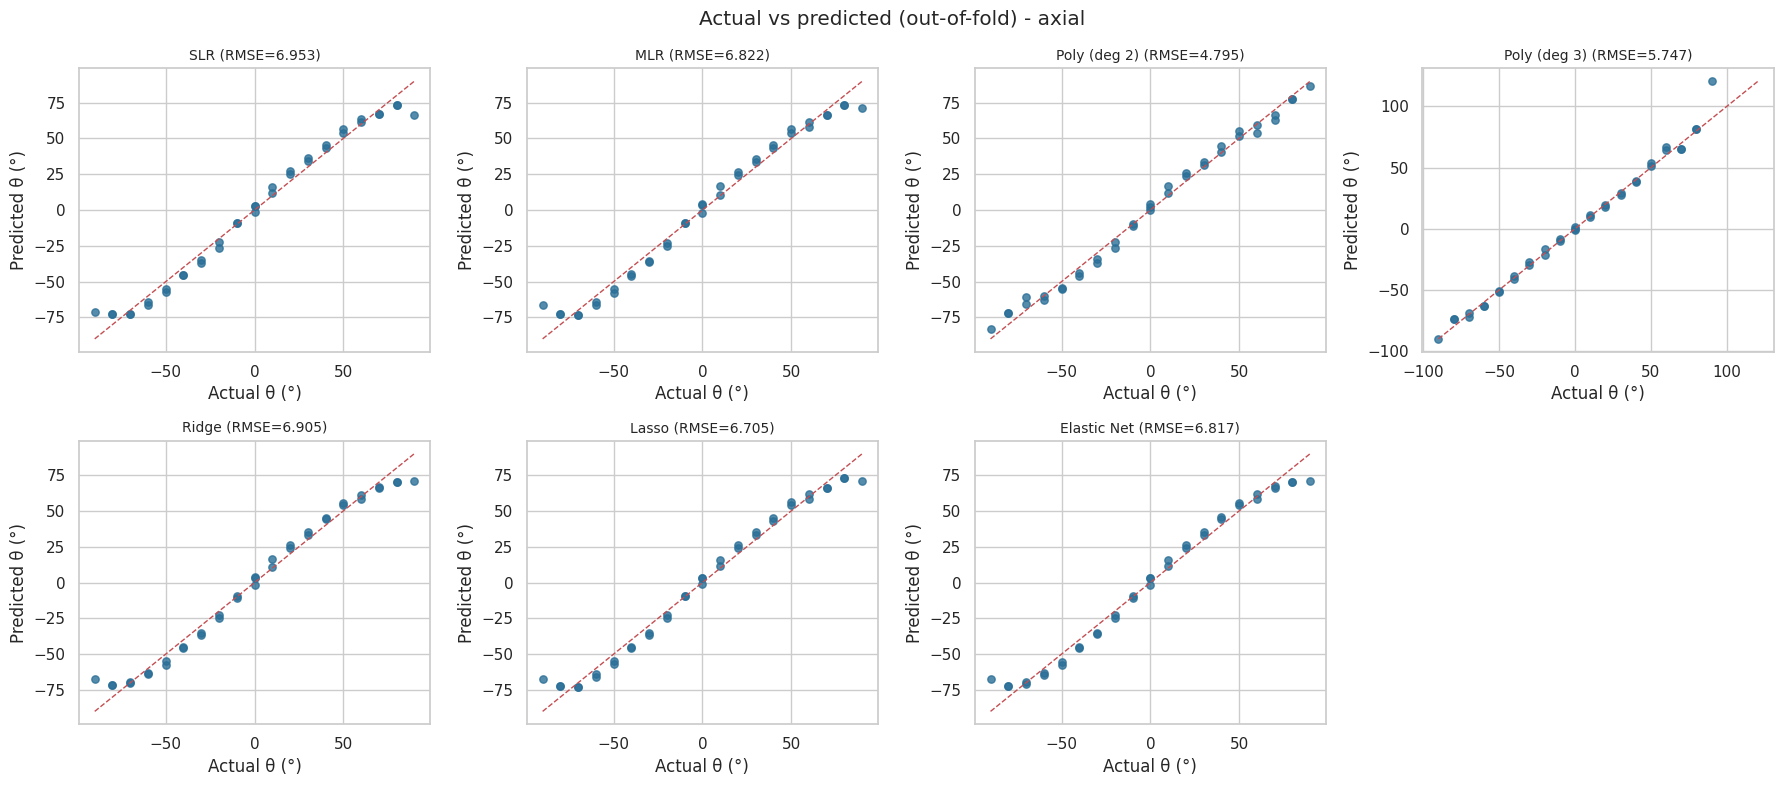


===== TRANSVERSE - statistical models (grouped 5-fold CV, features F1) =====
                   MAE         MSE      RMSE       R2     Time
SLR           44.91579  2682.86642  51.79639 -0.01499  0.00336
MLR           39.09203  2110.91394  45.94468  0.20139  0.00219
Poly (deg 2)  23.97709   946.14111  30.75941  0.64205  0.00283
Poly (deg 3)  16.46104   408.19862  20.20393  0.84557  0.00287
Ridge         38.69439  2072.11115  45.52045  0.21607  0.17042
Lasso         38.39587  2048.88784  45.26464  0.22486  0.17045
Elastic Net   41.78613  2363.78314  48.61875  0.10573  0.43619
  Ridge: alpha/l1_ratio chosen per outer fold -> [{'alpha': 0.00316}, {'alpha': 0.0001}, {'alpha': 0.001}, {'alpha': 0.0001}, {'alpha': 0.0001}]
  Lasso: alpha/l1_ratio chosen per outer fold -> [{'alpha': 0.1}, {'alpha': 0.0001}, {'alpha': 0.0001}, {'alpha': 0.0001}, {'alpha': 0.0001}]
  Elastic Net: alpha/l1_ratio chosen per outer fold -> [{'alpha': 0.00032, 'l1_ratio': 0.5}, {'alpha': 0.0001, 'l1_ratio': 0.8}, {'

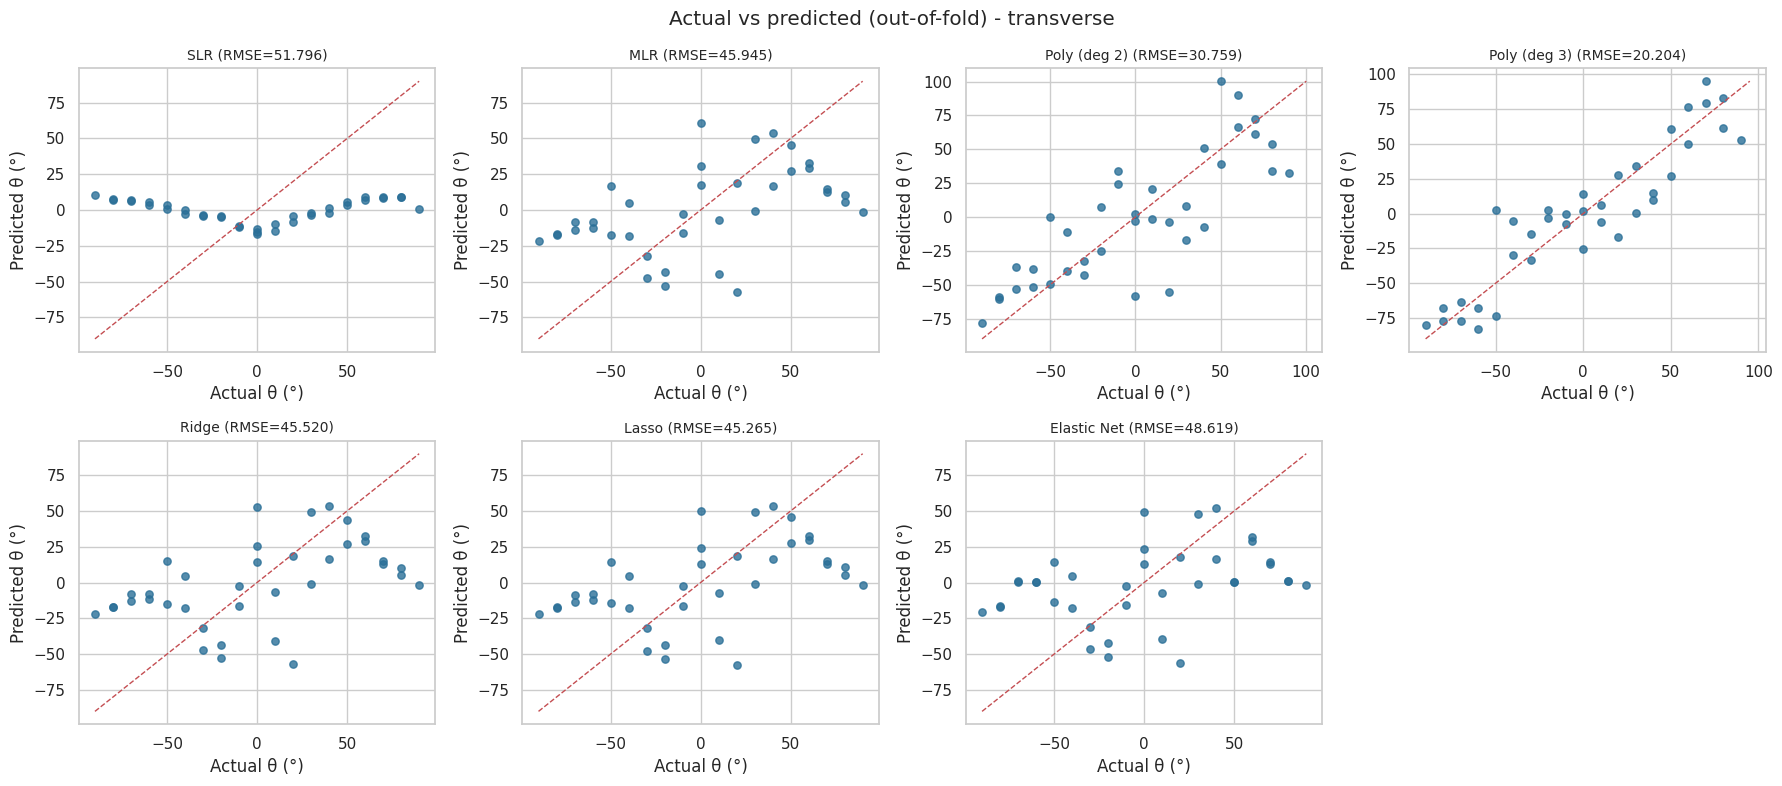


Effect of polynomial degree:
   Dataset  Degree  Train_RMSE   CV_RMSE     CV_R2
     axial       1      5.4927    6.8223    0.9824
     axial       2      3.8889    4.7948    0.9913
     axial       3      1.2483    5.7467    0.9875
     axial       4      0.9069   18.4757    0.8709
     axial       5      0.5617 1037.0576 -405.8821
transverse       1     42.7749   45.9447    0.2014
transverse       2     24.8367   30.7594    0.6421
transverse       3     15.3431   20.2039    0.8456
transverse       4     12.8778  148.9076   -7.3887
transverse       5      8.3199  311.6801  -35.7520


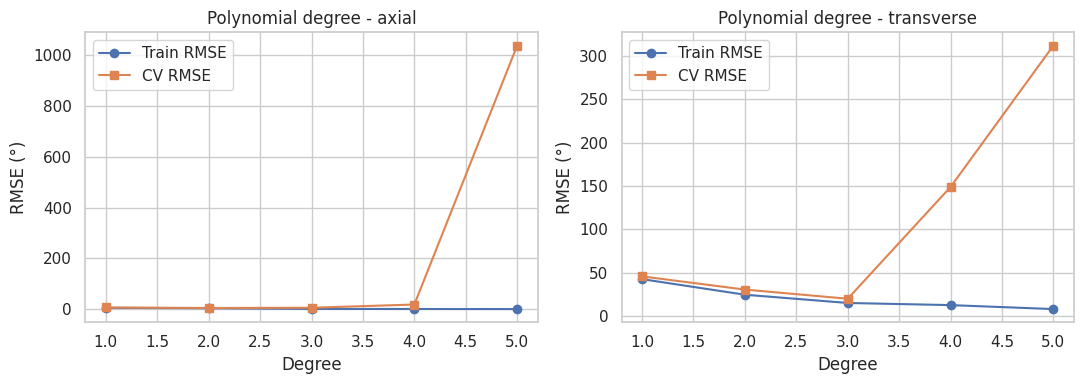

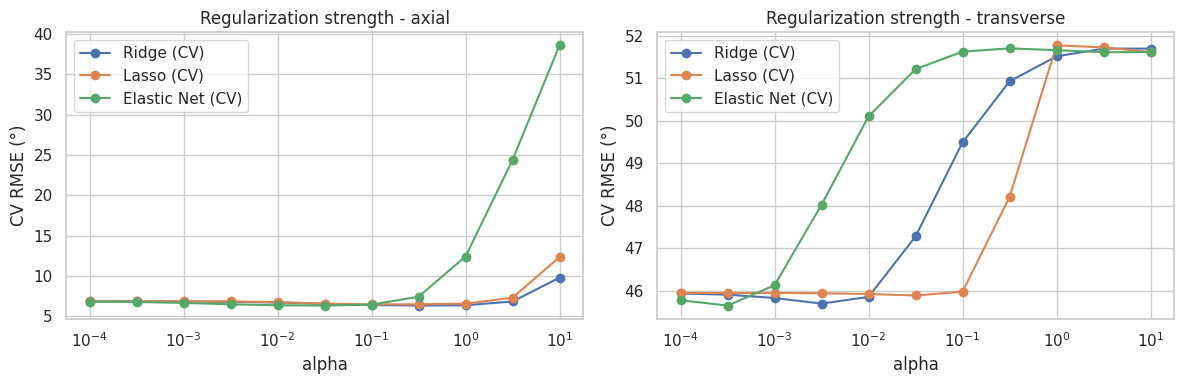

In [16]:
# TASK 4: Traditional statistical regression
from sklearn.linear_model import Ridge, Lasso, ElasticNet

class BestSingleFeature(BaseEstimator, TransformerMixin):
    """Simple linear regression: picks the single input most correlated with θ (chosen on TRAINING data only)."""
    def fit(self, X, y):
        X = np.asarray(X)
        self.idx_ = int(np.argmax(np.nan_to_num([abs(np.corrcoef(X[:, j], y)[0, 1]) for j in range(X.shape[1])]))); return self
    def transform(self, X): return np.asarray(X)[:, [self.idx_]]

def pipe(*steps): return Pipeline([('sc', StandardScaler()), *steps])
ALPHAS = np.logspace(-4, 1, 11)
STAT = {
    'SLR':          (Pipeline([('sel', BestSingleFeature()), ('sc', StandardScaler()), ('m', LinearRegression())]), None),
    'MLR':          (pipe(('m', LinearRegression())), None),
    'Poly (deg 2)': (pipe(('pf', PolynomialFeatures(2, include_bias=False)), ('m', LinearRegression())), None),
    'Poly (deg 3)': (pipe(('pf', PolynomialFeatures(3, include_bias=False)), ('m', LinearRegression())), None),
    'Ridge':        (pipe(('m', Ridge())), {'m__alpha': ALPHAS}),
    'Lasso':        (pipe(('m', Lasso(max_iter=200000, random_state=SEED))), {'m__alpha': ALPHAS}),
    'Elastic Net':  (pipe(('m', ElasticNet(max_iter=200000, random_state=SEED))), {'m__alpha': ALPHAS, 'm__l1_ratio': [0.2, 0.5, 0.8]}),
}
STAT_ORDER = list(STAT)
RES = {ds: {} for ds in DATA}

def avp(ax, y, p, title):
    ax.scatter(y, p, s=28, alpha=.8, color='#2a6f97')
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max()); ax.plot([lo, hi], [lo, hi], 'r--', lw=1)
    ax.set_title(title, fontsize=10); ax.set_xlabel('Actual θ (°)'); ax.set_ylabel('Predicted θ (°)')

for ds in DATA:
    X, y, g = get_xyg(ds)
    for name, (est, grid) in STAT.items():
        r = cv_eval(est, X, y, g, grid); r['Family'] = 'Statistical'; RES[ds][name] = r
    t = pd.DataFrame({n: {k: RES[ds][n][k] for k in ['MAE', 'MSE', 'RMSE', 'R2', 'Time']} for n in STAT_ORDER}).T
    print(f'\n===== {ds.upper()} - statistical models (grouped 5-fold CV, features {FEAT_MAIN}) ====='); print(t.round(5))
    for n in ['Ridge', 'Lasso', 'Elastic Net']:
        print(f'  {n}: alpha/l1_ratio chosen per outer fold ->', [{k.split("__")[1]: round(float(v), 5) for k, v in b.items()} for b in RES[ds][n]['best']])
    fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
    for ax, n in zip(axes, STAT_ORDER): avp(ax, y, RES[ds][n]['oof'], f'{n} (RMSE={RES[ds][n]["RMSE"]:.3f})')
    axes[-1].axis('off'); fig.suptitle(f'Actual vs predicted (out-of-fold) - {ds}'); plt.tight_layout()
    plt.savefig(f'figs/t4_avp_{ds}.png', dpi=200); plt.show()


rows = []
for ds in DATA:
    X, y, g = get_xyg(ds)
    for deg in range(1, 6):
        r = cv_eval(pipe(('pf', PolynomialFeatures(deg, include_bias=False)), ('m', LinearRegression())), X, y, g)
        rows.append(dict(Dataset=ds, Degree=deg, Train_RMSE=r['TrainRMSE'], CV_RMSE=r['RMSE'], CV_R2=r['R2']))
DEG_TABLE = pd.DataFrame(rows); print('\nEffect of polynomial degree:'); print(DEG_TABLE.round(4).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, ds in zip(axes, DATA):
    t = DEG_TABLE[DEG_TABLE.Dataset == ds]; ax.plot(t.Degree, t.Train_RMSE, 'o-', label='Train RMSE'); ax.plot(t.Degree, t.CV_RMSE, 's-', label='CV RMSE')
    ax.set_title(f'Polynomial degree - {ds}'); ax.set_xlabel('Degree'); ax.set_ylabel('RMSE (°)'); ax.legend()
plt.tight_layout(); plt.savefig('figs/t4_degree.png', dpi=200); plt.show()

rows = []
for ds in DATA:
    X, y, g = get_xyg(ds)
    for nm, cls, kw in [('Ridge', Ridge, {}), ('Lasso', Lasso, dict(max_iter=200000)), ('Elastic Net', ElasticNet, dict(l1_ratio=0.5, max_iter=200000))]:
        for a in ALPHAS:
            r = cv_eval(pipe(('m', cls(alpha=a, **kw))), X, y, g)
            rows.append(dict(Dataset=ds, Model=nm, alpha=a, Train_RMSE=r['TrainRMSE'], CV_RMSE=r['RMSE']))
REG_TABLE = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ds in zip(axes, DATA):
    for nm in ['Ridge', 'Lasso', 'Elastic Net']:
        t = REG_TABLE[(REG_TABLE.Dataset == ds) & (REG_TABLE.Model == nm)]; ax.plot(t.alpha, t.CV_RMSE, 'o-', label=f'{nm} (CV)')
    ax.set_xscale('log'); ax.set_title(f'Regularization strength - {ds}'); ax.set_xlabel('alpha'); ax.set_ylabel('CV RMSE (°)'); ax.legend()
plt.tight_layout(); plt.savefig('figs/t4_alpha.png', dpi=200); plt.show()

task 5

Hyperparameter comparison (fixed values):
   Dataset             Model       Setting     MAE    RMSE      R2   Time
     axial               SVR kernel=linear  5.4174  7.4273  0.9791 0.0108
     axial               SVR    kernel=rbf  1.5577  1.9870  0.9985 0.0053
     axial     Decision Tree   max_depth=2 20.7321 21.8662  0.8191 0.0018
     axial     Decision Tree   max_depth=3 13.7658 14.3186  0.9224 0.0018
     axial     Decision Tree   max_depth=5 10.2703 10.3975  0.9591 0.0018
     axial     Random Forest    n_trees=50  6.7946  7.8776  0.9765 0.0843
     axial     Random Forest   n_trees=100  6.6892  7.7849  0.9771 0.1808
     axial               KNN           k=3  6.2162  7.8843  0.9765 0.0021
     axial               KNN           k=5  6.2703  7.5838  0.9782 0.0021
     axial               KNN           k=7  7.6062  9.6805  0.9645 0.0021
     axial Gradient Boosting       lr=0.01  8.6045 10.7229  0.9565 0.1704
     axial Gradient Boosting        lr=0.1  8.5263  9.2219  0.9678 0.1

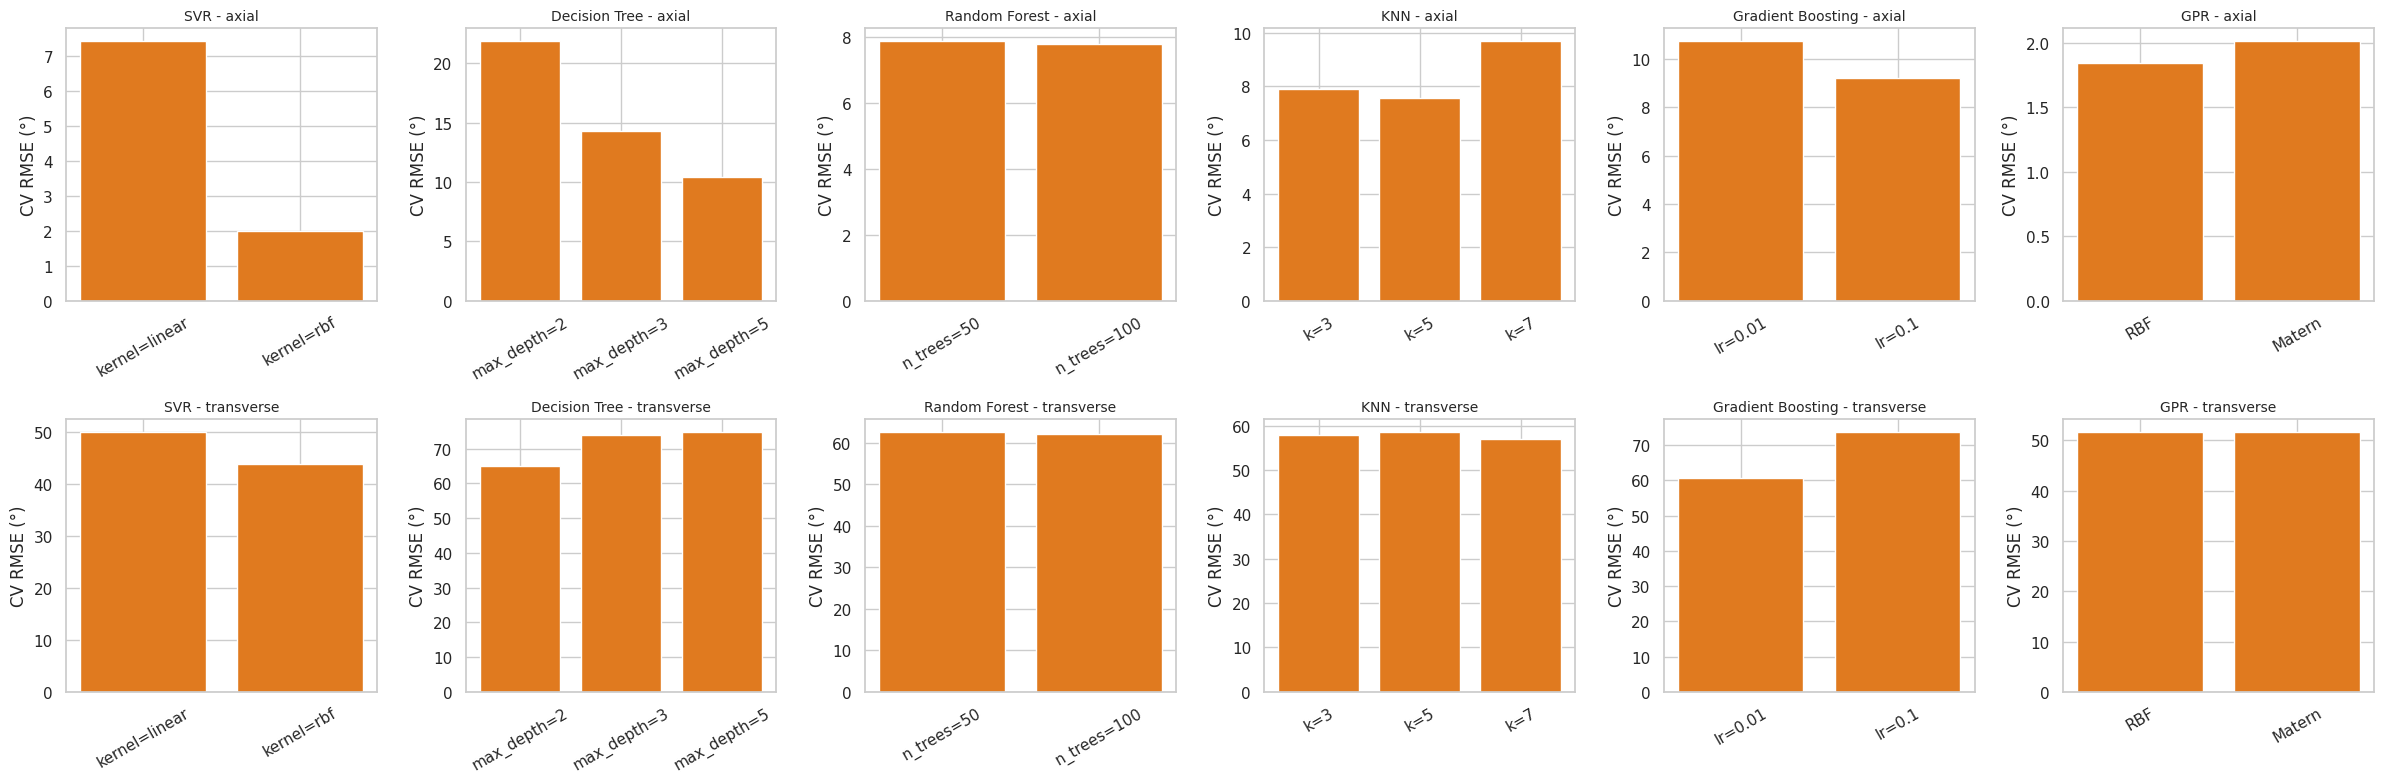


===== AXIAL - ML models (nested tuning, grouped 5-fold CV) =====
                        MAE        MSE      RMSE       R2     Time
SVR                 1.66532    4.38066   2.09300  0.99834  0.11903
Decision Tree      10.27027  108.10811  10.39750  0.95910  0.03569
Random Forest       6.86216   62.58243   7.91091  0.97632  1.13936
KNN                 6.57658   67.11111   8.19214  0.97461  0.03650
Gradient Boosting   8.52630   85.04272   9.22186  0.96783  0.86675
GPR                 1.41871    3.73505   1.93263  0.99859  0.61323
  SVR: chosen per fold -> [{'C': 100, 'kernel': 'rbf'}, {'C': 100, 'kernel': 'rbf'}, {'C': 100, 'kernel': 'rbf'}, {'C': 10, 'kernel': 'rbf'}, {'C': 100, 'kernel': 'rbf'}]
  Decision Tree: chosen per fold -> [{'max_depth': 5}, {'max_depth': 5}, {'max_depth': 5}, {'max_depth': 5}, {'max_depth': 5}]
  Random Forest: chosen per fold -> [{'n_estimators': 100}, {'n_estimators': 50}, {'n_estimators': 50}, {'n_estimators': 100}, {'n_estimators': 50}]
  KNN: chosen per 

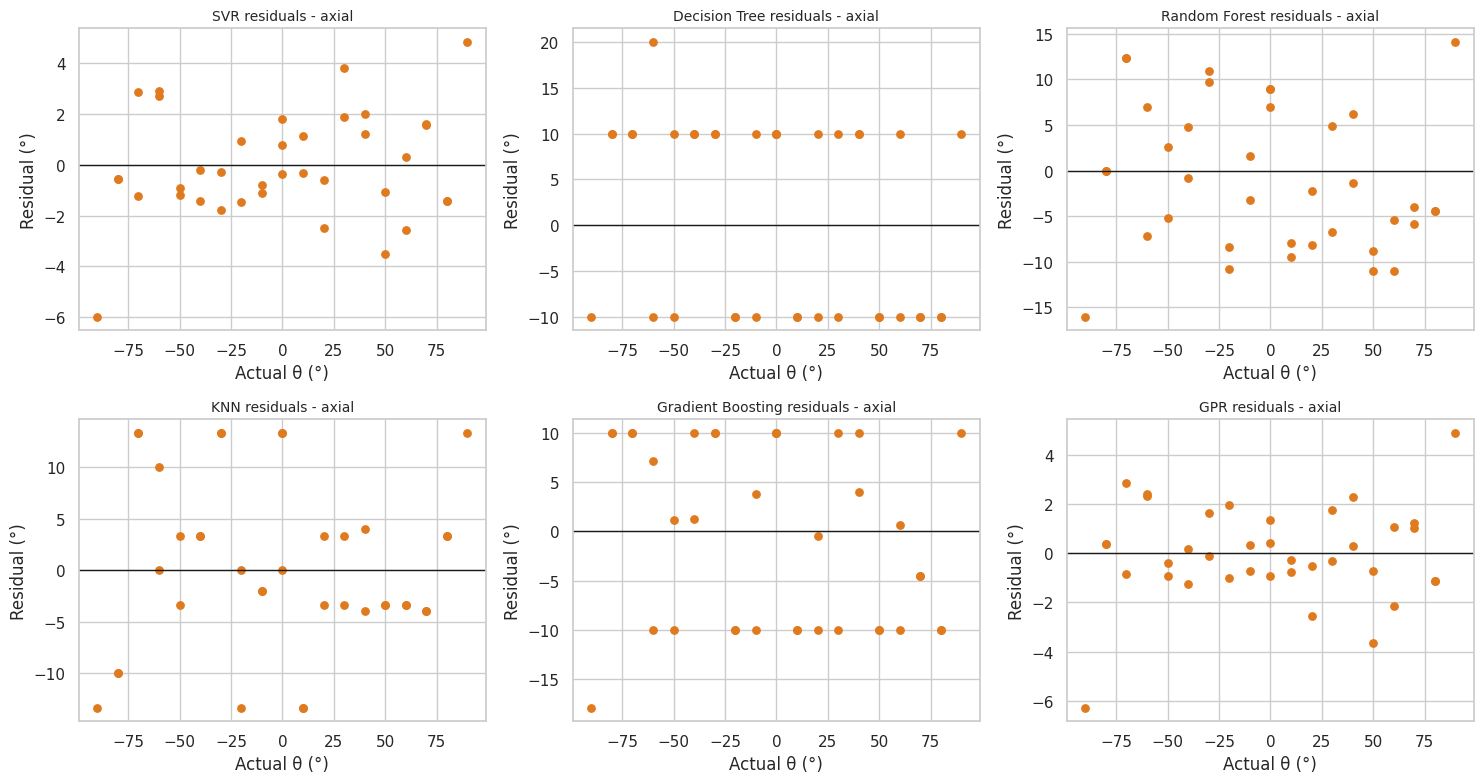

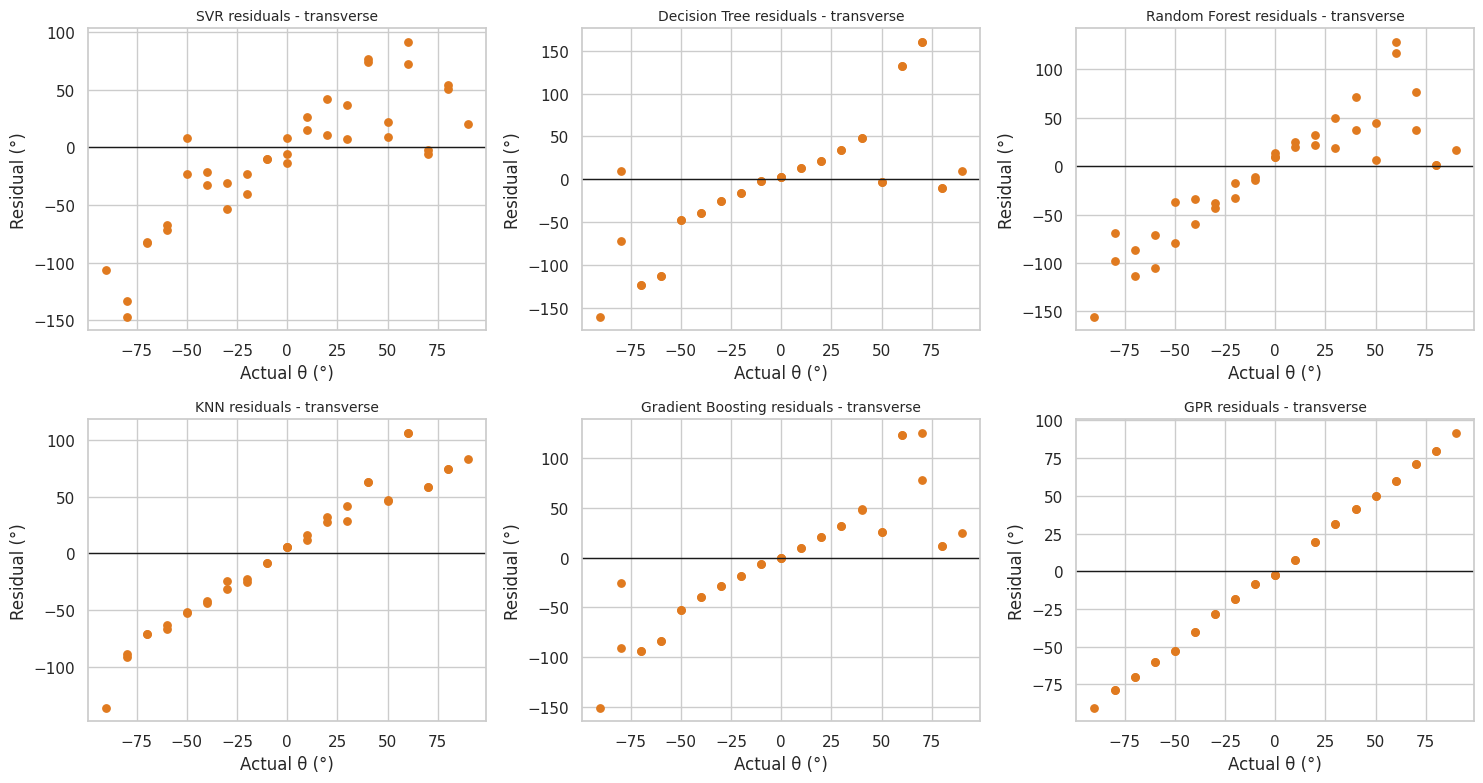


Mean |error| per tilt angle - GPR (axial):
theta
-90    6.2790
-80    0.3817
-70    1.8621
-60    2.3841
-50    0.6639
-40    0.7207
-30    0.8802
-20    1.4834
-10    0.5325
 0     0.8921
 10    0.5264
 20    1.5413
 30    1.0333
 40    1.2829
 50    2.1872
 60    1.5958
 70    1.1140
 80    1.1323
 90    4.8933

Mean |error| per tilt angle - GPR (transverse):
theta
-90    90.3333
-80    78.6207
-70    70.0000
-60    60.0000
-50    52.6667
-40    40.3333
-30    28.3333
-20    18.3333
-10     8.6207
 0      2.6667
 10     7.3333
 20    19.6667
 30    31.6667
 40    41.3793
 50    50.0000
 60    59.6667
 70    71.3793
 80    80.0000
 90    91.6667


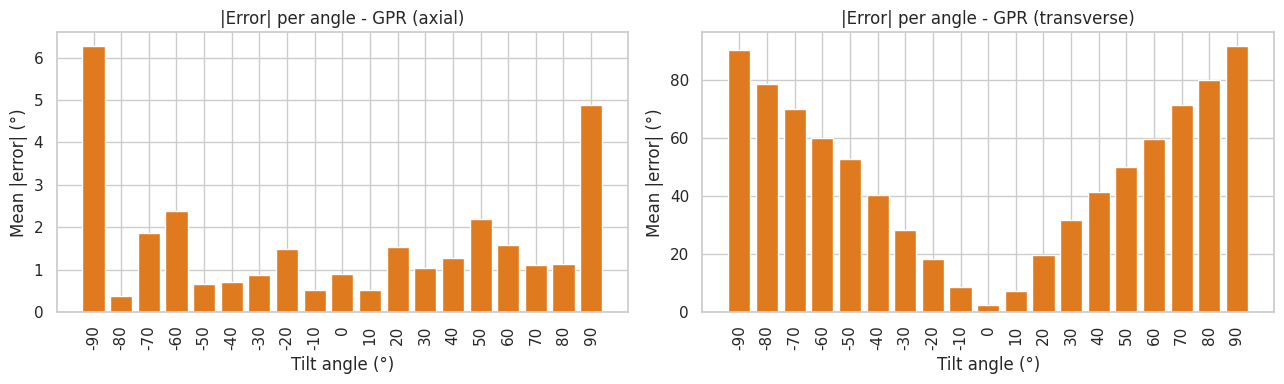

In [17]:
# TASK 5: Conventional ML regression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as C, WhiteKernel
from sklearn.compose import TransformedTargetRegressor

k_rbf = C(1.0) * RBF(1.0) + WhiteKernel(1e-2)
k_mat = C(1.0) * Matern(1.0, nu=2.5) + WhiteKernel(1e-2)
ML = {
    'SVR': dict(est=pipe(('m', TransformedTargetRegressor(regressor=SVR(C=100, epsilon=0.01), transformer=StandardScaler()))),
                hp={'kernel=linear': {'m__regressor__kernel': 'linear'}, 'kernel=rbf': {'m__regressor__kernel': 'rbf'}},
                grid={'m__regressor__kernel': ['linear', 'rbf'], 'm__regressor__C': [1, 10, 100]}),
    'Decision Tree': dict(est=pipe(('m', DecisionTreeRegressor(random_state=SEED))),
                hp={f'max_depth={d}': {'m__max_depth': d} for d in (2, 3, 5)}, grid={'m__max_depth': [2, 3, 5]}),
    'Random Forest': dict(est=pipe(('m', RandomForestRegressor(random_state=SEED, n_jobs=-1))),
                hp={f'n_trees={n}': {'m__n_estimators': n} for n in (50, 100)}, grid={'m__n_estimators': [50, 100]}),
    'KNN': dict(est=pipe(('m', KNeighborsRegressor())),
                hp={f'k={k}': {'m__n_neighbors': k} for k in (3, 5, 7)}, grid={'m__n_neighbors': [3, 5, 7]}),
    'Gradient Boosting': dict(est=pipe(('m', GradientBoostingRegressor(n_estimators=200, max_depth=2, random_state=SEED))),
                hp={f'lr={l}': {'m__learning_rate': l} for l in (0.01, 0.1)}, grid={'m__learning_rate': [0.01, 0.1]}),
    'GPR': dict(est=pipe(('m', GaussianProcessRegressor(kernel=k_rbf, normalize_y=True, n_restarts_optimizer=2, random_state=SEED))),
                hp={'RBF': {'m__kernel': k_rbf}, 'Matern': {'m__kernel': k_mat}}, grid={'m__kernel': [k_rbf, k_mat]}),
}
ML_ORDER = list(ML)

def short(bp):
    return {k.split('__')[-1]: ('Matern' if 'Matern' in str(v) else 'RBF' if 'RBF' in str(v) else v) for k, v in bp.items()}


rows = []
for ds in DATA:
    X, y, g = get_xyg(ds)
    for name, spec in ML.items():
        for lab, p in spec['hp'].items():
            r = cv_eval(clone(spec['est']).set_params(**p), X, y, g)
            rows.append(dict(Dataset=ds, Model=name, Setting=lab, MAE=r['MAE'], RMSE=r['RMSE'], R2=r['R2'], Time=r['Time']))
HP_TABLE = pd.DataFrame(rows); print('Hyperparameter comparison (fixed values):'); print(HP_TABLE.round(4).to_string(index=False))
fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for i, ds in enumerate(DATA):
    for j, name in enumerate(ML_ORDER):
        t = HP_TABLE[(HP_TABLE.Dataset == ds) & (HP_TABLE.Model == name)]
        axes[i, j].bar(t.Setting, t.RMSE, color='#e07a1f'); axes[i, j].set_title(f'{name} - {ds}', fontsize=10)
        axes[i, j].tick_params(axis='x', rotation=30); axes[i, j].set_ylabel('CV RMSE (°)')
plt.tight_layout(); plt.savefig('figs/t5_hyperparams.png', dpi=200); plt.show()


for ds in DATA:
    X, y, g = get_xyg(ds)
    for name, spec in ML.items():
        r = cv_eval(spec['est'], X, y, g, spec['grid']); r['Family'] = 'ML'; RES[ds][name] = r
    t = pd.DataFrame({n: {k: RES[ds][n][k] for k in ['MAE', 'MSE', 'RMSE', 'R2', 'Time']} for n in ML_ORDER}).T
    print(f'\n===== {ds.upper()} - ML models (nested tuning, grouped 5-fold CV) ====='); print(t.round(5))
    for n in ML_ORDER: print(f'  {n}: chosen per fold ->', [short(b) for b in RES[ds][n]['best']])
    print(f'  >>> Best conventional ML model ({ds}): {t.RMSE.idxmin()} (RMSE={t.RMSE.min():.4f}°)')

for ds in DATA:
    X, y, g = get_xyg(ds)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
    for ax, n in zip(axes, ML_ORDER):
        res = y - RES[ds][n]['oof']; ax.scatter(y, res, s=28, color='#e07a1f'); ax.axhline(0, color='k', lw=1)
        ax.set_title(f'{n} residuals - {ds}', fontsize=10); ax.set_xlabel('Actual θ (°)'); ax.set_ylabel('Residual (°)')
    plt.tight_layout(); plt.savefig(f'figs/t5_resid_{ds}.png', dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ds in zip(axes, DATA):
    X, y, g = get_xyg(ds); best = min(ML_ORDER, key=lambda n: RES[ds][n]['RMSE'])
    err = pd.DataFrame({'theta': y, 'abs_err': np.abs(y - RES[ds][best]['oof'])}).groupby('theta').abs_err.mean()
    print(f'\nMean |error| per tilt angle - {best} ({ds}):'); print(err.round(4).to_string())
    ax.bar(err.index.astype(str), err.values, color='#e07a1f'); ax.set_title(f'|Error| per angle - {best} ({ds})')
    ax.set_xlabel('Tilt angle (°)'); ax.set_ylabel('Mean |error| (°)'); ax.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.savefig('figs/t5_per_angle.png', dpi=200); plt.show()

task 6


===== AXIAL tilt prediction - grouped 5-fold CV (mean fit time per fold, incl. inner tuning) =====
                        Family       MAE        MSE      RMSE       R2  Training Time (s)
SLR                Statistical   5.42835   48.34303   6.95292  0.98171            0.00233
MLR                Statistical   5.35829   46.54434   6.82234  0.98239            0.00163
Poly (deg 2)       Statistical   4.09002   22.99012   4.79480  0.99130            0.00200
Poly (deg 3)       Statistical   2.89979   33.02500   5.74674  0.98751            0.00207
Ridge              Statistical   5.24544   47.67662   6.90483  0.98196            0.11808
Lasso              Statistical   5.21720   44.95964   6.70520  0.98299            0.13442
Elastic Net        Statistical   5.15665   46.47679   6.81739  0.98242            0.38710
SVR                         ML   1.66532    4.38066   2.09300  0.99834            0.11903
Decision Tree               ML  10.27027  108.10811  10.39750  0.95910            0.03569


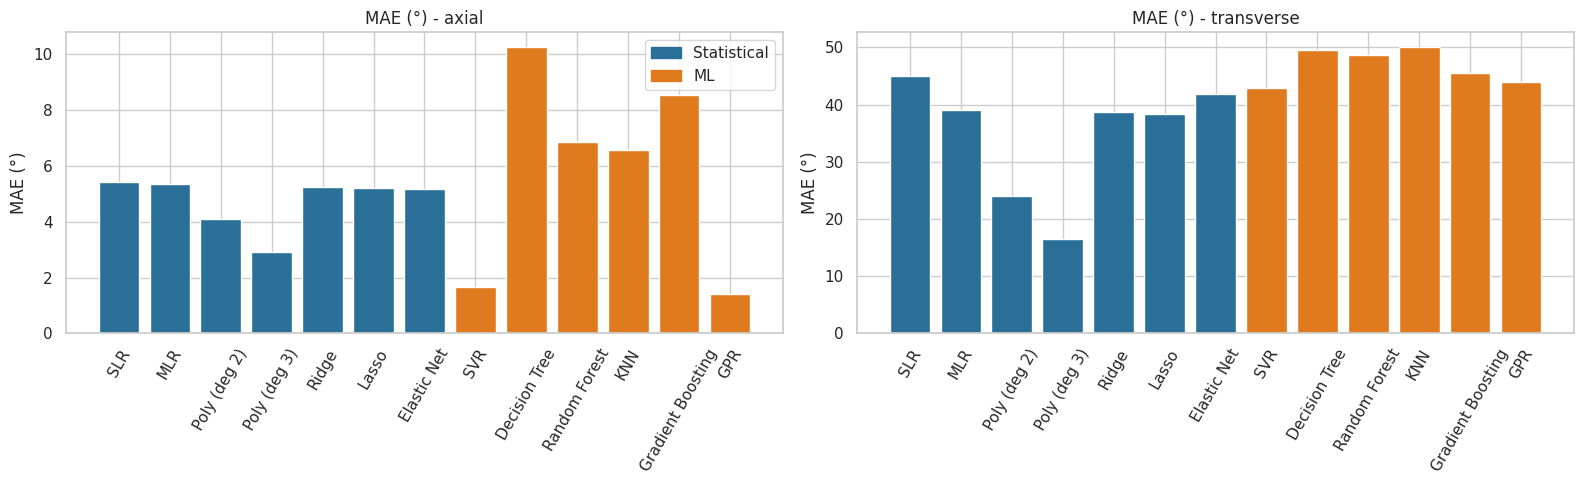

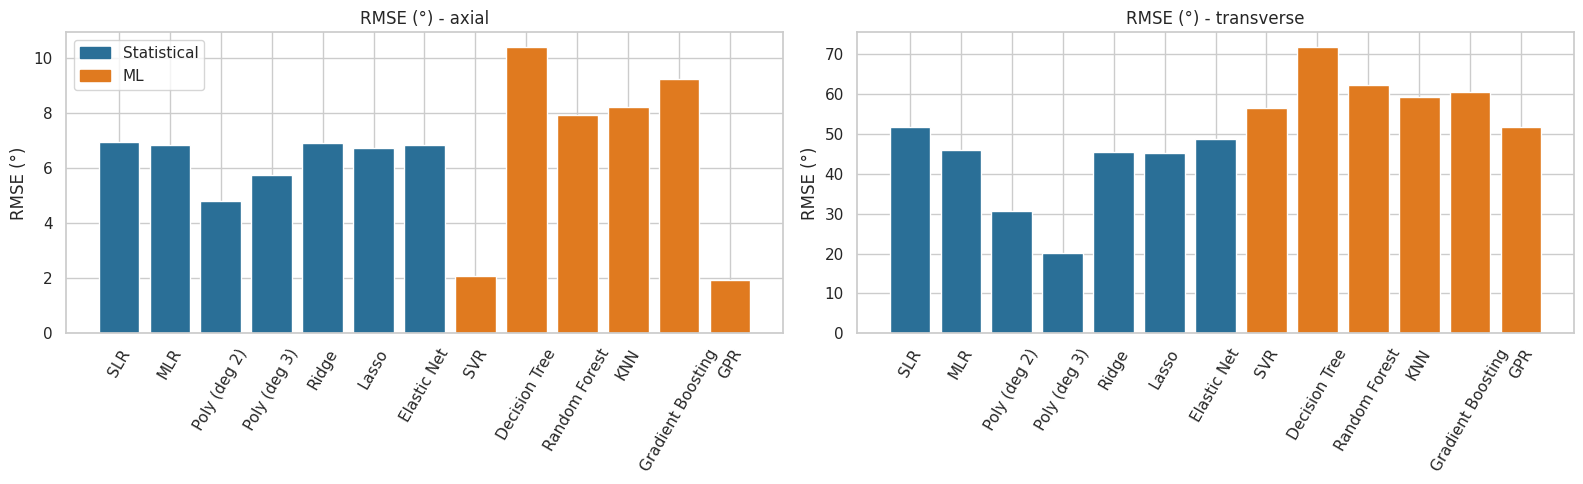

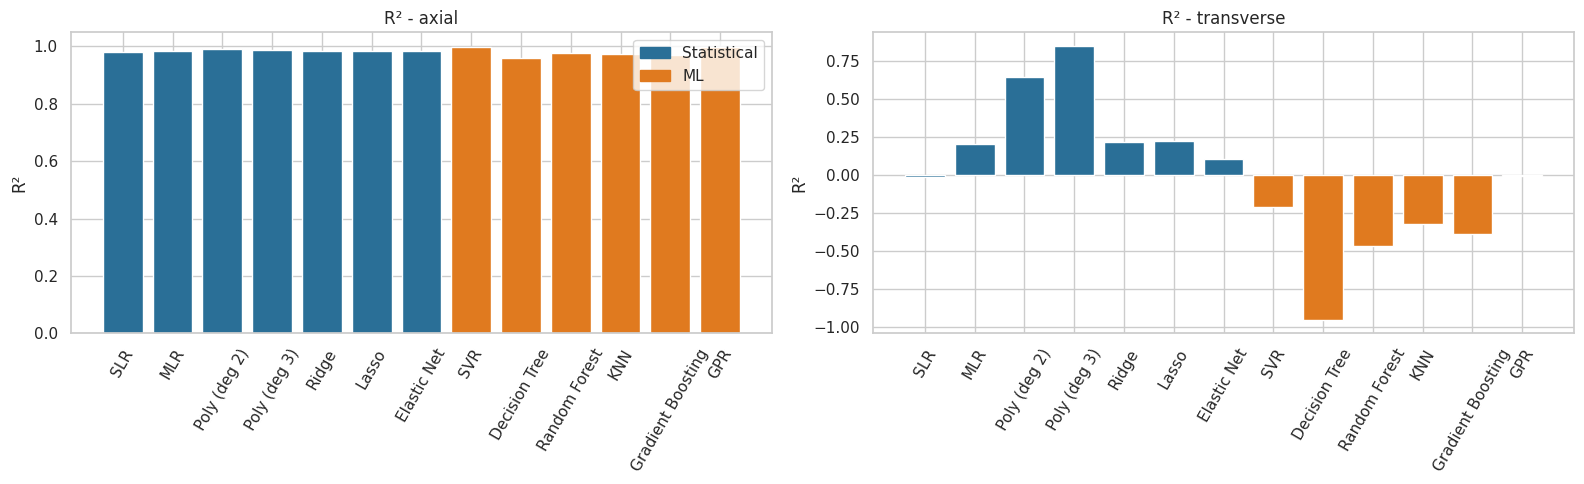


Selected models: {'axial': {'stat': 'Poly (deg 2)', 'ml': 'GPR'}, 'transverse': {'stat': 'Poly (deg 3)', 'ml': 'GPR'}}


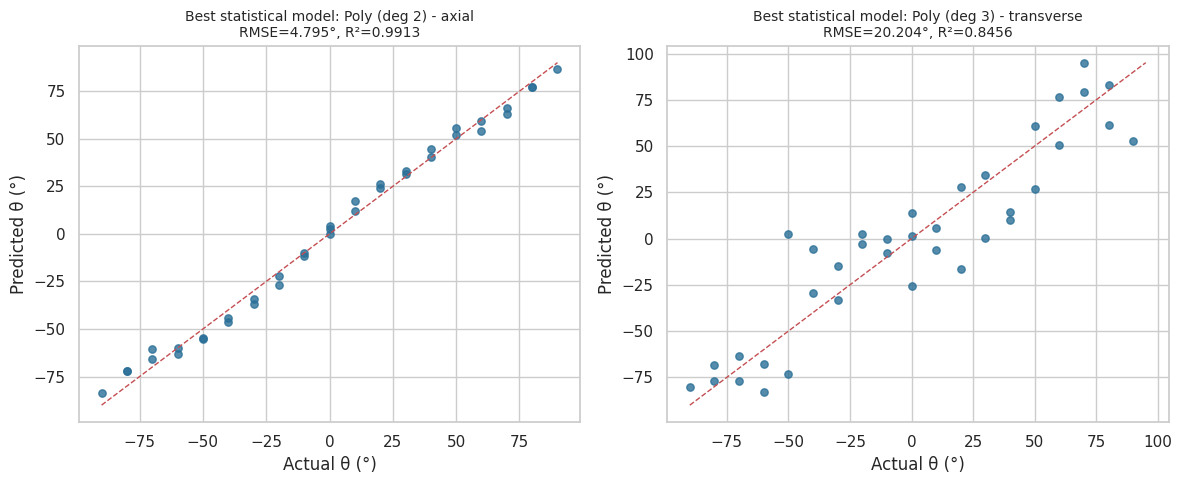

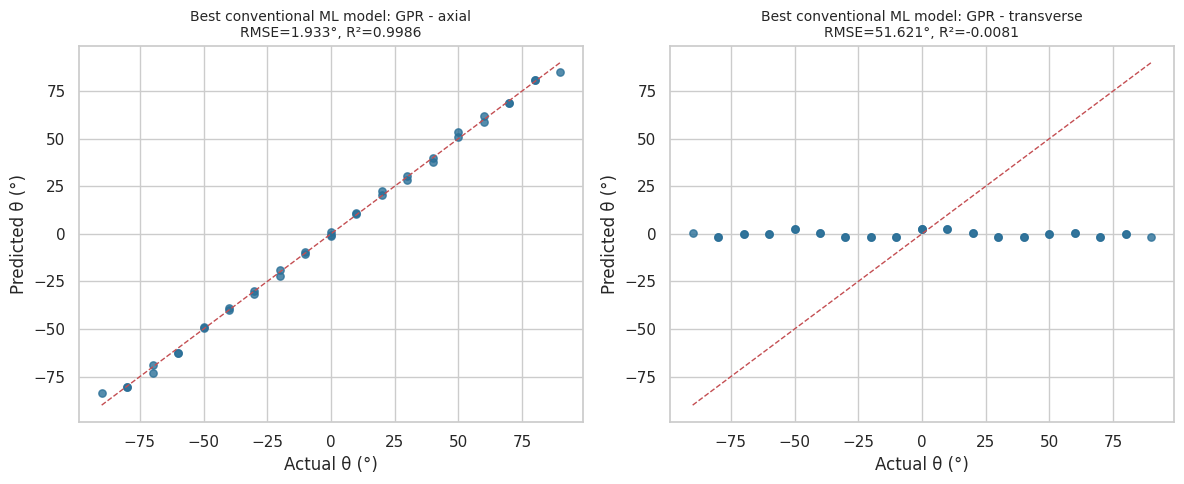

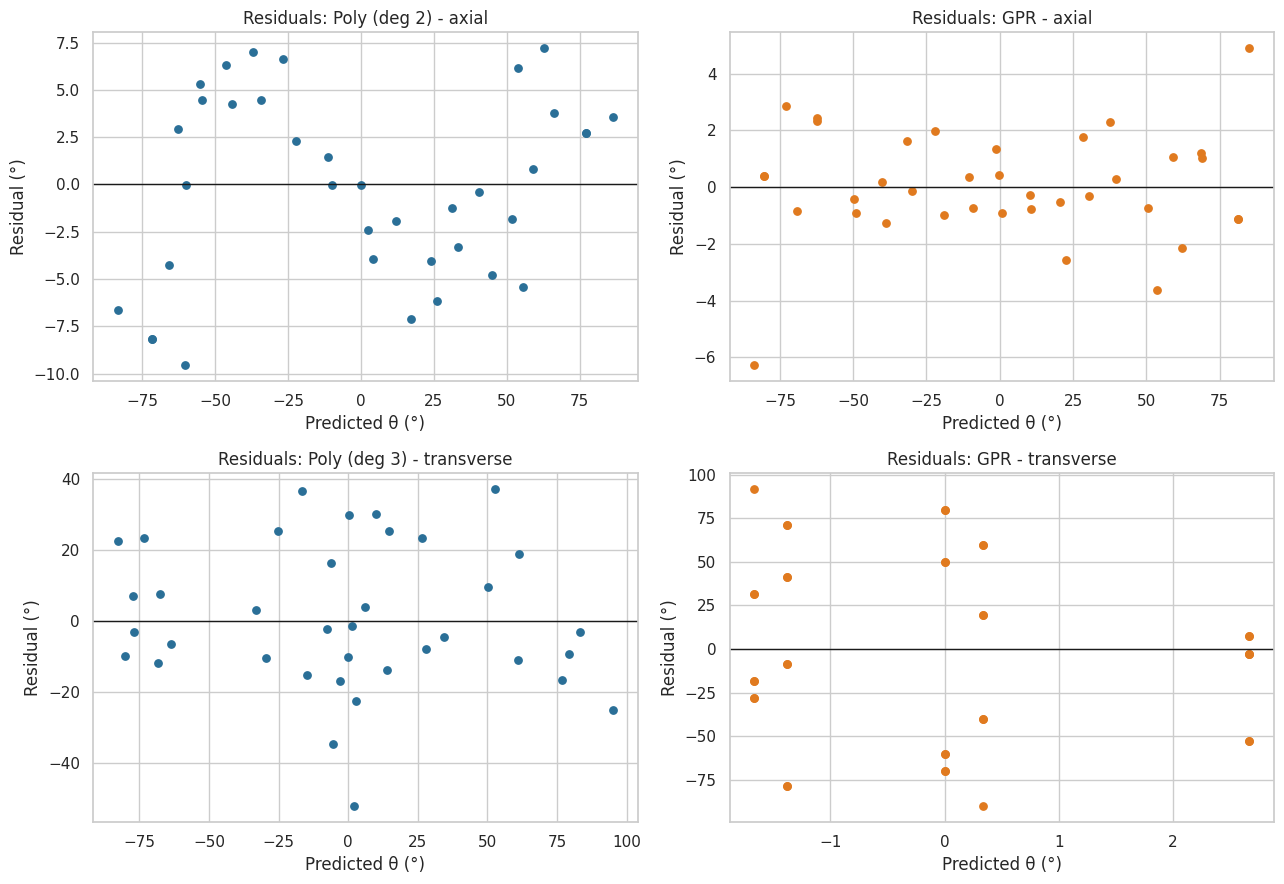

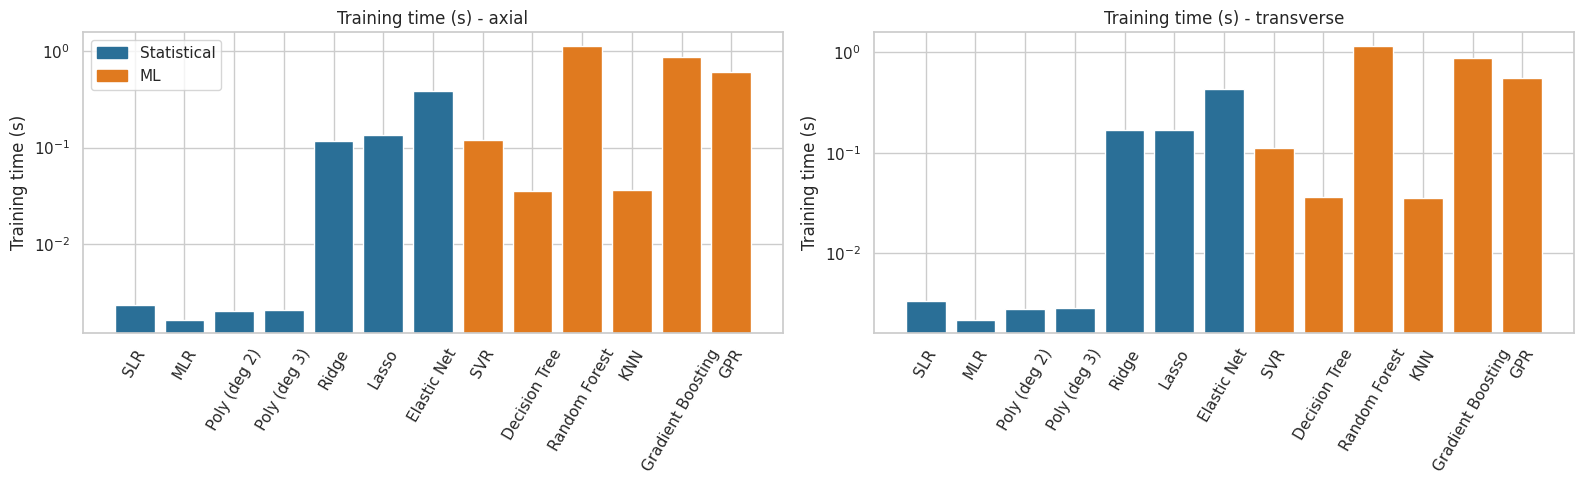

[axial] Lowest RMSE overall: GPR (1.9326°, R²=0.9986); best statistical: Poly (deg 2) (4.7948°); best ML: GPR (1.9326°); fastest: MLR.
[transverse] Lowest RMSE overall: Poly (deg 3) (20.2039°, R²=0.8456); best statistical: Poly (deg 3) (20.2039°); best ML: GPR (51.6212°); fastest: MLR.


In [18]:
#  TASK 6: Performance comparison (tables + 7 graphs)
from matplotlib.patches import Patch
PAL = {'Statistical': '#2a6f97', 'ML': '#e07a1f'}
TABLE = {}
for ds in DATA:
    rows = {n: dict(Family=RES[ds][n]['Family'], MAE=RES[ds][n]['MAE'], MSE=RES[ds][n]['MSE'], RMSE=RES[ds][n]['RMSE'],
                    R2=RES[ds][n]['R2'], **{'Training Time (s)': RES[ds][n]['Time']}) for n in STAT_ORDER + ML_ORDER}
    TABLE[ds] = pd.DataFrame(rows).T.astype({'MAE': float, 'MSE': float, 'RMSE': float, 'R2': float, 'Training Time (s)': float})
    TABLE[ds].to_csv(f'results_{ds}.csv')
    print(f'\n===== {ds.upper()} tilt prediction - grouped 5-fold CV (mean fit time per fold, incl. inner tuning) =====')
    print(TABLE[ds].round(5))

def bar_cmp(metric, fname, ylabel, log=False):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, ds in zip(axes, DATA):
        t = TABLE[ds]; ax.bar(t.index, t[metric], color=[PAL[f] for f in t.Family])
        ax.set_title(f'{ylabel} - {ds}'); ax.set_ylabel(ylabel); ax.tick_params(axis='x', rotation=60)
        if log: ax.set_yscale('log')
    axes[0].legend(handles=[Patch(color=c, label=k) for k, c in PAL.items()])
    plt.tight_layout(); plt.savefig(f'figs/{fname}.png', dpi=200); plt.show()

bar_cmp('MAE', 'g1_mae', 'MAE (°)')
bar_cmp('RMSE', 'g2_rmse', 'RMSE (°)')
bar_cmp('R2', 'g3_r2', 'R²')
BEST = {ds: dict(stat=TABLE[ds][TABLE[ds].Family == 'Statistical'].RMSE.idxmin(),
                 ml=TABLE[ds][TABLE[ds].Family == 'ML'].RMSE.idxmin()) for ds in DATA}
print('\nSelected models:', BEST)
for key, gnum, title in [('stat', 'g4_best_stat', 'Best statistical model'), ('ml', 'g5_best_ml', 'Best conventional ML model')]:   # Graphs 4, 5
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, ds in zip(axes, DATA):
        X, y, g = get_xyg(ds); n = BEST[ds][key]; avp(ax, y, RES[ds][n]['oof'], f'{title}: {n} - {ds}\nRMSE={RES[ds][n]["RMSE"]:.3f}°, R²={RES[ds][n]["R2"]:.4f}')
    plt.tight_layout(); plt.savefig(f'figs/{gnum}.png', dpi=200); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for i, ds in enumerate(DATA):
    X, y, g = get_xyg(ds)
    for j, key in enumerate(['stat', 'ml']):
        n = BEST[ds][key]; p = RES[ds][n]['oof']; ax = axes[i, j]
        ax.scatter(p, y - p, s=28, color=PAL['Statistical' if key == 'stat' else 'ML']); ax.axhline(0, color='k', lw=1)
        ax.set_title(f'Residuals: {n} - {ds}'); ax.set_xlabel('Predicted θ (°)'); ax.set_ylabel('Residual (°)')
plt.tight_layout(); plt.savefig('figs/g6_residuals.png', dpi=200); plt.show()
bar_cmp('Training Time (s)', 'g7_time', 'Training time (s)', log=True)


for ds in DATA:
    t = TABLE[ds]; b = t.RMSE.idxmin()
    print(f'[{ds}] Lowest RMSE overall: {b} ({t.RMSE.min():.4f}°, R²={t.R2[b]:.4f}); best statistical: {BEST[ds]["stat"]} ({t.RMSE[BEST[ds]["stat"]]:.4f}°); '
          f'best ML: {BEST[ds]["ml"]} ({t.RMSE[BEST[ds]["ml"]]:.4f}°); fastest: {t["Training Time (s)"].idxmin()}.')

task 7

In [19]:
#  TASK 7: Result interpretation
LINEAR = ['SLR', 'MLR', 'Ridge', 'Lasso', 'Elastic Net']
def base_est(n): return STAT[n][0] if n in STAT else ML[n]['est']
print('Q1/Q2 - best models');
for ds in DATA:
    t = TABLE[ds]; print(f'  {ds}: best statistical = {BEST[ds]["stat"]} (RMSE {t.RMSE[BEST[ds]["stat"]]:.4f}°) | best ML = {BEST[ds]["ml"]} (RMSE {t.RMSE[BEST[ds]["ml"]]:.4f}°)')

print('\nQ3 - nonlinear vs linear')
for ds in DATA:
    t = TABLE[ds]; lin = t.loc[LINEAR].RMSE; non = t.drop(LINEAR).RMSE
    print(f'  {ds}: best linear {lin.idxmin()} {lin.min():.4f}° | best nonlinear {non.idxmin()} {non.min():.4f}° | mean RMSE linear {lin.mean():.4f}° vs nonlinear {non.mean():.4f}° '
          f'-> nonlinear {"WINS" if non.min() < lin.min() else "does NOT win"} on best-model RMSE')

print('\nQ4 - feature configuration effect (CV RMSE):'); print(FEAT_TABLE[['Dataset', 'Config', 'Features', 'MLR_RMSE', 'Poly2_RMSE']].round(4).to_string(index=False))
print('\nQ5 - model complexity (polynomial degree: train vs CV error):'); print(DEG_TABLE.round(4).to_string(index=False))
for ds in DATA:
    t = DEG_TABLE[DEG_TABLE.Dataset == ds]; print(f'  {ds}: lowest CV RMSE at degree {int(t.loc[t.CV_RMSE.idxmin(), "Degree"])}; train error keeps falling while CV error {"rises" if t.CV_RMSE.iloc[-1] > t.CV_RMSE.min() else "does not rise"} at high degree')

print('\nQ6 - axial vs transverse (sensitivity and repeatability)')
for ds, df in DATA.items():
    s1, s2 = np.polyfit(df.theta, df.dL1, 1)[0], np.polyfit(df.theta, df.dL2, 1)[0]
    sd = df.groupby('theta')[['dL1', 'dL2']].std().dropna()
    print(f'  {ds}: slope dL1={s1:.5f} nm/°, dL2={s2:.5f} nm/°, theta range=[{df.theta.min()}, {df.theta.max()}], '
          f'mean repeat-std dL1/dL2={sd.mean().round(5).tolist() if len(sd) else "n/a"}, best RMSE={TABLE[ds].RMSE.min():.4f}°')

print('\nQ7 - real-time suitability (RMSE, per-fold training time, single-sample inference latency)')
for ds in DATA:
    X, y, g = get_xyg(ds); lat = {}
    for n in STAT_ORDER + ML_ORDER:
        m = clone(base_est(n)).fit(X, y); x1 = X[:1]; t0 = time.perf_counter()
        for _ in range(100): m.predict(x1)
        lat[n] = (time.perf_counter() - t0) / 100 * 1000
    t = TABLE[ds].copy(); t['Latency (ms)'] = pd.Series(lat)
    ok = t[t.RMSE <= 1.10 * t.RMSE.min()]; rec = ok['Latency (ms)'].idxmin()
    print(f'\n[{ds}]'); print(t[['RMSE', 'R2', 'Training Time (s)', 'Latency (ms)']].round(5))
    print(f'  Candidates within 10% of best RMSE: {list(ok.index)} -> lowest-latency recommendation: {rec}')

Q1/Q2 - best models
  axial: best statistical = Poly (deg 2) (RMSE 4.7948°) | best ML = GPR (RMSE 1.9326°)
  transverse: best statistical = Poly (deg 3) (RMSE 20.2039°) | best ML = GPR (RMSE 51.6212°)

Q3 - nonlinear vs linear
  axial: best linear Lasso 6.7052° | best nonlinear GPR 1.9326° | mean RMSE linear 6.8405° vs nonlinear 6.2862° -> nonlinear WINS on best-model RMSE
  transverse: best linear Lasso 45.2646° | best nonlinear Poly (deg 3) 20.2039° | mean RMSE linear 47.4290° vs nonlinear 51.6313° -> nonlinear WINS on best-model RMSE

Q4 - feature configuration effect (CV RMSE):
   Dataset Config   Features  MLR_RMSE  Poly2_RMSE
     axial     F1    dL1+dL2    6.8223      4.7948
     axial     F2      dDiff    6.2762      6.5364
     axial     F3       dAvg   57.0475     55.1035
     axial     F4 dDiff+dAvg    6.8223      4.7948
transverse     F1    dL1+dL2   45.9447     30.7594
transverse     F2      dDiff   51.8692     53.1484
transverse     F3       dAvg   51.8411     51.9131
tra

task 8

Transverse angles: min=-90, max=90, negative angles present: True

Signed vs absolute prediction (grouped 5-fold CV):
        Model   Target     MAE    RMSE      R2
          MLR signed θ 41.9972 48.3381  0.1160
          MLR      |θ|  4.2789  5.0897  0.9643
 Poly (deg 2) signed θ 28.0043 35.3184  0.5281
 Poly (deg 2)      |θ|  3.8361  5.0286  0.9652
    SVR (RBF) signed θ 30.6938 40.7109  0.3730
    SVR (RBF)      |θ|  5.3500  6.1993  0.9471
Random Forest signed θ 48.3351 62.6492 -0.4849
Random Forest      |θ|  9.9622 11.1729  0.8281
    GPR (RBF) signed θ 43.7838 51.4125  0.0000
    GPR (RBF)      |θ|  4.8911  5.8368  0.9531


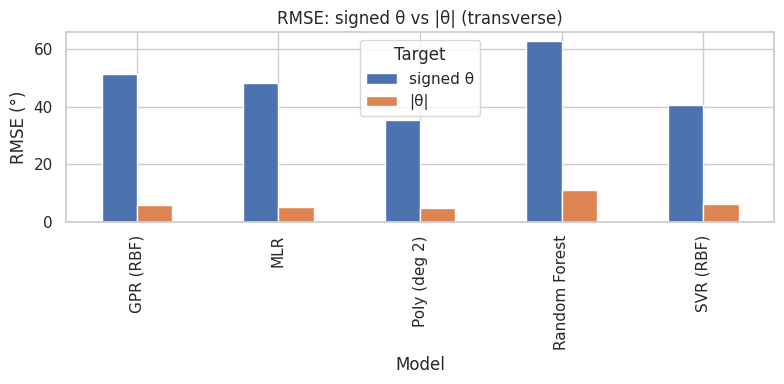


Sign classification accuracy from [Δλ1, Δλ2] (grouped CV): 0.575  (0.5 = chance)

Mean Δλ at +θ vs -θ for the same |θ|:
         dL1           dL2        dDiff      
theta     -1      1     -1      1    -1     1
a                                            
10      21.5   44.0   12.5   31.0   9.0  13.0
20      53.0   82.5   37.5   68.5  15.5  14.0
30      95.5  125.0   78.5  114.5  17.0  10.5
40     147.5  176.5  131.0  165.0  16.5  11.5
50     194.0  229.5  175.0  215.0  19.0  14.5
60     238.5  274.0  215.0  254.5  23.5  19.5
70     275.5  312.5  249.5  288.5  26.0  24.0
80     300.0  321.5  271.5  296.0  28.5  25.5
90     315.0  321.0  285.0  295.0  30.0  26.0


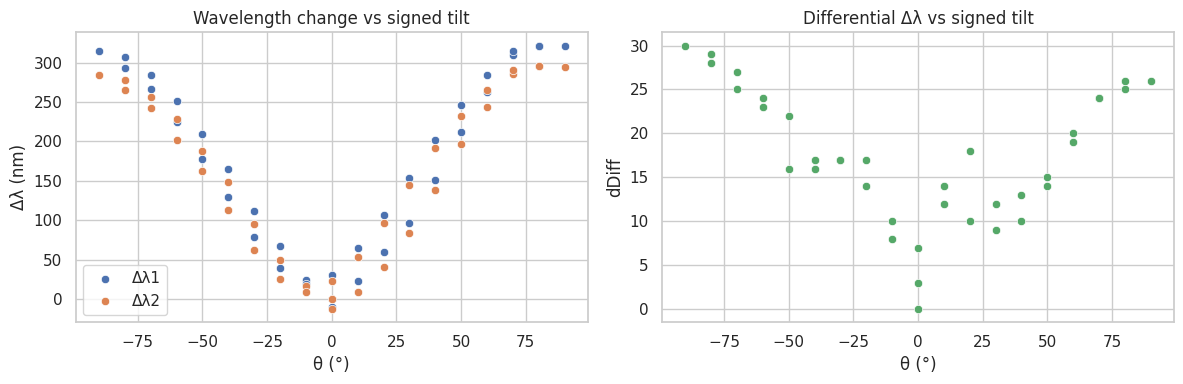

In [20]:
#  ADVANCED TASK C: Signed vs absolute tilt (transverse)
from sklearn.linear_model import LogisticRegression
ds = 'transverse'; d = FE[ds]
has_neg = bool((d.theta < 0).any())
print(f'Transverse angles: min={d.theta.min()}, max={d.theta.max()}, negative angles present: {has_neg}')

models = {'MLR': STAT['MLR'][0], 'Poly (deg 2)': STAT['Poly (deg 2)'][0],
          'SVR (RBF)': clone(ML['SVR']['est']).set_params(**ML['SVR']['hp']['kernel=rbf']),
          'Random Forest': clone(ML['Random Forest']['est']).set_params(**ML['Random Forest']['hp']['n_trees=100']),
          'GPR (RBF)': clone(ML['GPR']['est']).set_params(**ML['GPR']['hp']['RBF'])}
Xs = d[FEATS[FEAT_MAIN]].values
grp = d.theta.abs().round(4).values
rows, preds = [], {}
for n, est in models.items():
    for tgt, y in [('signed θ', d.theta.values), ('|θ|', d.theta.abs().values)]:
        r = cv_eval(est, Xs, y, grp); preds[(n, tgt)] = r['oof']
        rows.append(dict(Model=n, Target=tgt, MAE=r['MAE'], RMSE=r['RMSE'], R2=r['R2']))
TC = pd.DataFrame(rows); print('\nSigned vs absolute prediction (grouped 5-fold CV):'); print(TC.round(4).to_string(index=False))
piv = TC.pivot(index='Model', columns='Target', values='RMSE'); piv.plot.bar(figsize=(8, 4), title='RMSE: signed θ vs |θ| (transverse)'); plt.ylabel('RMSE (°)')
plt.tight_layout(); plt.savefig('figs/advC_rmse.png', dpi=200); plt.show()

if has_neg:
    nz = d.theta != 0
    clf = Pipeline([('sc', StandardScaler()), ('m', LogisticRegression())])
    acc = []
    for tr, te in GroupKFold(n_splits=min(5, len(np.unique(grp[nz])))).split(Xs[nz], np.sign(d.theta[nz]), grp[nz]):
        m = clone(clf).fit(Xs[nz][tr], np.sign(d.theta[nz].values[tr])); acc.append(m.score(Xs[nz][te], np.sign(d.theta[nz].values[te])))
    print(f'\nSign classification accuracy from [Δλ1, Δλ2] (grouped CV): {np.mean(acc):.3f}  (0.5 = chance)')
    pairs = d[nz].assign(a=d.theta[nz].abs()).groupby(['a', np.sign(d.theta[nz])])[['dL1', 'dL2', 'dDiff']].mean().unstack()
    print('\nMean Δλ at +θ vs -θ for the same |θ|:'); print(pairs.round(5))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.scatterplot(x=d.theta, y=d.dL1, ax=ax[0], label='Δλ1'); sns.scatterplot(x=d.theta, y=d.dL2, ax=ax[0], label='Δλ2')
    ax[0].set_title('Wavelength change vs signed tilt'); ax[0].set_xlabel('θ (°)'); ax[0].set_ylabel('Δλ (nm)')
    sns.scatterplot(x=d.theta, y=d.dDiff, ax=ax[1], color='g'); ax[1].set_title('Differential Δλ vs signed tilt'); ax[1].set_xlabel('θ (°)')
    plt.tight_layout(); plt.savefig('figs/advC_sign.png', dpi=200); plt.show()
else:
    print('\nNo negative transverse angles in this sheet, so |θ| = θ and the two targets are identical; '
          'the sheet cannot show whether the sensor distinguishes +θ from -θ.')